<a href="https://colab.research.google.com/github/rgaratac/natural_dust_service_tool/blob/main/Dust_deduction_tool.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Natural Dust Service Tool

This notebook presents the **CAMS Natural Dust Service Tool**, which supports EU Member States in identifying and quantifying the contribution of natural dust to measured $PM_{10}$ and $PM_{2.5}$ concentrations, as required under Article 16 of the revised Ambient Air Quality Directive (Directive (EU) 2024/2881). The tool estimates the natural dust contribution and subtracts it from the measured concentrations, yielding dust-corrected surface $PM_{10}$ and $PM_{2.5}$ values.

> AAQD (2024/2881) Article 16: Member states are requested to identify a) zones where exceedances of limit values for a given pollutant are attributable to natural sources and b) average exposure territorial units, where exceedances of the level determined by the average exposure reduction obligations are attributable to natural sources.

The Natural Dust Service Tool implements the methodology set out in the European Commission guidelines for assessing natural contributions from dust (cite new guideline). The guidance explains how to identify and quantify natural dust contributions before subtracting them from measured PM concentrations. The CAMS interim reanalysis dust product is used to identify days affected by natural dust.

# Outline
- [1 - Import packages](#1)
- [2 - Country selection and threshold settings](#2)
- [3 - Download data](#3)
- [4 - Data preparation](#4)
- [5 - Station pairing](#5)
- [6 - Flag dust days with CAMS data](#6)
- [7 - Calculate the dust contribution](#7)
- [8 - Save or load results](#8)
- [9 - Visualization](#9)

Created by Jessie Zhang and Roger Garatachea Solé, TNO
          22/05/2026


<a name="1"></a>
## **1 - Import packages**

Run the cell below to load the required packages and the helper functions. If everything loads correctly, the last line of the output reads:

> util.py has been imported


In [ ]:
#@title Load packages and helper modules (double-click to show the code)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import requests
import os
import glob
import zipfile
import calendar
#!pip install xarray netcdf4
import xarray as xr
!pip install cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
# %pip uninstall plotly -y
# %pip install "plotly>=5.24.0"
from importlib.metadata import version as _pkg_version
# Plotly 6 widgets bundle their own JS, so the maps also render in VS Code.
if int(_pkg_version('plotly').split('.')[0]) < 6:
    %pip install -q "plotly>=6" anywidget
import plotly
import urllib.request
import json
import io
import importlib.util
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:  # no 'google' package at all (local Python)
    IN_COLAB = False
try:
    # Pin to the latest commit: raw.githubusercontent.com caches 'main' for several minutes.
    _sha = requests.get("https://api.github.com/repos/rgaratac/natural_dust_service_tool/commits/main",
                        headers={"Accept": "application/vnd.github.sha"}, timeout=10).text.strip()
except Exception:
    _sha = ""
raw_base = f"https://raw.githubusercontent.com/rgaratac/natural_dust_service_tool/{_sha if len(_sha) == 40 else 'main'}"
for name in ["util.py", "cams_data_to_eea_daily.py", "pairing.py",
             "natural_contribution.py", "pairing_viz.py", "dust_threshold_sensitivity.py",
             "exceedance_report.py"]:
    # Locally the repo copies are kept, so local edits are not overwritten.
    if IN_COLAB or not Path(name).exists():
        urllib.request.urlretrieve(f"{raw_base}/{name}", Path(name))
import importlib, util, pairing, natural_contribution, pairing_viz, exceedance_report
# Re-running this cell picks up edited modules without restarting the kernel.
for _mod in (util, pairing, natural_contribution, pairing_viz, exceedance_report):
    importlib.reload(_mod)
from util import *
import pairing as pr
import natural_contribution as nc
import pairing_viz as pv
import exceedance_report as er
print(until_check())

<details>
<summary><font size="2" color="darkgreen"><b>Troubleshooting</b></font></summary>

If a package fails to load, install it with `!pip install <package-name>` and run the cell again.

After editing `util.py` or another helper module, run the first cell again: it reloads the modules without restarting the session. To reload `util.py` on its own:

```
import importlib, util
importlib.reload(util)
```

The interactive map widgets are designed for Google Colab and may not work in VS Code or on an HPC system. In that case, use the static maps in section 9.3.

</details>


<a name="2"></a>
## **2 - Country selection and threshold settings**

Select one or more countries from the table below by listing their codes in `Countries`, then choose the year (`YEAR`), pollutant (`POLLUTANT`), dataset (`dataset`) and time resolution (`EEA_temporal_flag`, `hour` or `day`). For hourly data, `HOURLY_DAY_DEFINITION` sets the day used for the daily means of both the observations and CAMS: `'local'` (default, 00:00–24:00 local time of each station) or `'utc'` (00:00–24:00 UTC). Daily EEA data always use the station's local day.
The data only need to be downloaded and processed once; later runs reuse the stored files.

<details>
<summary><b>What each switch does</b></summary>

| Flag | First run | Later runs | What it does |
|---|---|---|---|
| `DOWNLOAD_EEA` | `True` | `False` | Downloads the EEA observations and stores them as a zip file |
| `DOWNLOAD_CAMS` | `True` | `False` | Downloads the CAMS interim reanalysis dust data |
| `COMPUTE_CAMS_DAILY` | `True` | `False` | Builds the daily CAMS product from the hourly zips. `hour` writes a UTC daily grid; `day` writes per-station local-day means. Turned on automatically when `DOWNLOAD_CAMS` is True |
| `LOAD_PARQUET_DATA` | `False` | `True` | Loads the saved Parquet file with the processed results instead of recomputing them |

</details>

<details>
<summary><b>Country codes</b></summary>

Codes of the EEA download service. Greece is `GR` (not `EL`). Not every country has data for every dataset and time resolution: daily (`day`) data only include stations that report daily values, and some countries report only hourly or only daily values.

| Code | Country | Code | Country |
|---|---|---|---|
| AD | Andorra | HU | Hungary |
| AL | Albania | IE | Ireland |
| AT | Austria | IS | Iceland |
| BA | Bosnia and Herzegovina | IT | Italy |
| BE | Belgium | LT | Lithuania |
| BG | Bulgaria | LU | Luxembourg |
| CH | Switzerland | LV | Latvia |
| CY | Cyprus | ME | Montenegro |
| CZ | Czechia | MK | North Macedonia |
| DE | Germany | MT | Malta |
| DK | Denmark | NL | Netherlands |
| EE | Estonia | NO | Norway |
| ES | Spain | PL | Poland |
| FI | Finland | PT | Portugal |
| FR | France | RO | Romania |
| GB | United Kingdom | RS | Serbia |
| GI | Gibraltar | SE | Sweden |
| GR | Greece | SI | Slovenia |
| HR | Croatia | SK | Slovakia |

</details>

<details>
<summary><b>EEA datasets (E1a or E2a)</b></summary>

1.   Verified data (`E1a`): Validated measurements available from 2013, reported annually by countries for the previous year.

2.   Up-to-date data (`E2a`): Unverified measurements transmitted continuously, available from 2023.

E2a daily aggregation does not have any station data for 2025.

</details>


In [ ]:
project_dir          = '.'
YEAR                 = 2025      # int: target year
EEA_temporal_flag    = 'day'    # 'hour' or 'day': time resolution of the EEA data
HOURLY_DAY_DEFINITION = 'local'  # hourly data: 'local' = 00-24 station local time, 'utc' = 00-24 UTC
dataset              = 'E1a'     # E1a or E2a
POLLUTANT            = 'PM2.5'
EEA_folder_path      = f'EEA_{POLLUTANT}/{YEAR}/{dataset}/{EEA_temporal_flag}'
VAR                  = 'dust'
CAMS_folder_path     = f'{project_dir}/IRA_{VAR}/'
DOWNLOAD_EEA         = False
DOWNLOAD_CAMS        = False
COMPUTE_CAMS_DAILY   = False
USE_GOOGLE_DRIVE     = IN_COLAB  # Colab: keep outputs on Drive. Locally outputs go to project_dir.
Countries            = ["ES"]
# full list of countries
#Countries            =  ["AD", "AL", "AT", "BA", "BE", "BG", "CH", "CY", "CZ", "DE", "DK", "EE", "ES", "FI", "FR", "GB", "GI", "GR", "HR", "HU", "IE", "IS", "IT", "LT", "LU", "LV", "ME", "MK", "MT", "NL", "NO", "PL", "PT", "RO", "RS", "SE", "SI", "SK"]
LOAD_PARQUET_DATA    = True # if False then new data will be saved, only use it as True when everything has been computed

In [ ]:
#@title Apply the settings (double-click to show the code)

import cams_data_to_eea_daily as cams_daily

# Falls back to project_dir when Drive cannot be mounted (e.g. running locally).
OUTPUT_DIR, USE_GOOGLE_DRIVE = cams_daily.resolve_output_dirs(project_dir, USE_GOOGLE_DRIVE and IN_COLAB)
gdrive_output_dir = OUTPUT_DIR  # older cells use this name
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f'Output folder: {os.path.abspath(OUTPUT_DIR)}')

# DOWNLOAD_CAMS brings new hourly files, so the daily product has to be rebuilt.
# Which average is used follows EEA_temporal_flag (hour = UTC day, day = station local day).
_run = cams_daily.resolve_run_flags(
    download_eea=DOWNLOAD_EEA,
    download_cams=DOWNLOAD_CAMS,
    compute_cams_daily=COMPUTE_CAMS_DAILY,
    load_parquet=LOAD_PARQUET_DATA,
    eea_temporal_flag=EEA_temporal_flag,
)
DOWNLOAD_EEA = _run['download_eea']
DOWNLOAD_CAMS = _run['download_cams']
COMPUTE_CAMS_DAILY = _run['compute_cams_daily']
LOAD_PARQUET_DATA = _run['load_parquet']
for _note in _run['notes']:
    print(_note)
HOURLY_DAY_DEFINITION = globals().get('HOURLY_DAY_DEFINITION', 'utc')
if HOURLY_DAY_DEFINITION not in ('utc', 'local'):
    raise ValueError("HOURLY_DAY_DEFINITION must be 'utc' or 'local'.")
# Daily EEA data are always station local days; hourly data follow HOURLY_DAY_DEFINITION.
LOCAL_DAY = EEA_temporal_flag == 'day' or HOURLY_DAY_DEFINITION == 'local'
if EEA_temporal_flag == 'day':
    print("EEA daily data: observations and CAMS use each station's local day.")
elif LOCAL_DAY:
    print("EEA hourly data: observations and CAMS are averaged over each station's local day (00-24 local time).")
else:
    print('EEA hourly data: observations and CAMS are averaged over UTC days (00-24 UTC).')

# Defaults for the optional section 3.1.1, so later cells also run when it is skipped.
USE_USER_OBSERVATIONS = globals().get('USE_USER_OBSERVATIONS', False)
user_station_metadata = globals().get('user_station_metadata')


**Thresholds, limit values and method parameters**

The parameters below can be adjusted, for example to reflect future changes in the guidelines or limit values. The defaults can be kept for a standard run.

<details>
<summary><b>Thresholds and limit values</b></summary>

*   `CAMS_dust_threshold`: CAMS dust concentration (µg/m³) above which a day is flagged as a natural-event (dust) day.
*   `PM10_DAILY_LIMIT`, `PM25_DAILY_LIMIT`, `PM10_ANNUAL_LIMIT`, `PM25_ANNUAL_LIMIT`: limit values (µg/m³). The daily PM10 default is 45 µg/m³ (Directive (EU) 2024/2881); set 50 to use the previous limit. `POLLUTANT_daily_threshold` and `POLLUTANT_annual_threshold` follow `POLLUTANT`.
*   `Station_Temporal_coverage`: minimum annual data coverage (%) required for an EEA station to be included.

</details>

<details>
<summary><b>Station pairing (section 5)</b></summary>

*   `PAIRING_MODE`: `'default'` pairs each station with an RB (or UB) reference as described in section 5. `'none'` does not pair: every station is its own reference. RB stations use Option 1 on their own data (±`OPTION1_HALF_WINDOW` days, about 30 days) and all other stations use Option 2 self-calibration (±`OPTION2_HALF_WINDOW` days around the episode, 6 days). With `'none'` the limits below and `USE_USER_PAIRING` are ignored.
*   `MAX_RB_DISTANCE_KM`, `MAX_RB_ALTITUDE_DIFF_M`: a regional background (RB) station is a suitable reference only within this horizontal distance and altitude difference.
*   `MAX_UB_DISTANCE_KM`: maximum distance between a traffic/industrial (TH) station and its urban background (UB) reference.
*   `PAIR_SAME_COUNTRY`: only pair stations of the same country.
*   `USE_USER_PAIRING`: when True and `station_pairing_user.csv` exists in the output folder, it replaces the default pairing.
*   `REAPPLY_PAIRING_ON_LOAD`: when results are loaded from Parquet, recompute the deduction with the current pairing (the first and last 15 days of the year then have a shorter Option 1 window).

</details>

<details>
<summary><b>Methods (section 7)</b></summary>

*   `OPTION1_HALF_WINDOW` (15) and `OPTION2_HALF_WINDOW` (3): days before and after an event day (or an episode for Option 2) in the reference window. Event days are always excluded.
*   `REFERENCE_PERCENTILE` (50): percentile of the reference window.
*   `MIN_REFERENCE_DAYS_OPTION1`, `MIN_REFERENCE_DAYS_OPTION2`: minimum valid reference days; otherwise the day is flagged `insufficient_reference` and nothing is subtracted.

</details>


In [ ]:
##################User Editable######################
CAMS_dust_threshold         = 5         # unit: µg/m3 total dust

# Limit values, µg/m3 (Directive (EU) 2024/2881). Use PM10_DAILY_LIMIT = 50 for the previous limit.
PM10_DAILY_LIMIT            = 45
PM25_DAILY_LIMIT            = 25
PM10_ANNUAL_LIMIT           = 20
PM25_ANNUAL_LIMIT           = 10

Station_Temporal_coverage   = 65        # in % of temporal coverage per whole year for each EEA station

# Station pairing
PAIRING_MODE                = 'default' # 'default': pair with RB/UB references; 'none': no pairing
                                        # ('none': RB stations Option 1 on their own data, all others Option 2 self-calibration)
MAX_RB_DISTANCE_KM          = 100
MAX_RB_ALTITUDE_DIFF_M      = 500
MAX_UB_DISTANCE_KM          = 50
PAIR_SAME_COUNTRY           = True
USE_USER_PAIRING            = False     # True: use station_pairing_user.csv from the output folder
USER_PAIRING_FILE           = 'station_pairing_user.csv'
REAPPLY_PAIRING_ON_LOAD     = True

# Natural-contribution methods
OPTION1_HALF_WINDOW         = 15
OPTION2_HALF_WINDOW         = 3
REFERENCE_PERCENTILE        = 50
MIN_REFERENCE_DAYS_OPTION1  = 10
MIN_REFERENCE_DAYS_OPTION2  = 3
##################STOP Editing######################

In [ ]:
#@title Build the limit values and method parameters (double-click to show the code)

if PAIRING_MODE not in ('default', 'none'):
    raise ValueError("PAIRING_MODE must be 'default' or 'none'")
LIMITS = nc.LimitValues(PM10_DAILY_LIMIT, PM25_DAILY_LIMIT, PM10_ANNUAL_LIMIT, PM25_ANNUAL_LIMIT)
POLLUTANT_daily_threshold   = LIMITS.daily(POLLUTANT)
POLLUTANT_annual_threshold  = LIMITS.annual(POLLUTANT)
PAIRING_LIMITS = pr.PairingLimits(
    max_rb_distance_km=MAX_RB_DISTANCE_KM,
    max_rb_altitude_diff_m=MAX_RB_ALTITUDE_DIFF_M,
    max_ub_distance_km=MAX_UB_DISTANCE_KM,
    same_country=PAIR_SAME_COUNTRY,
)
METHOD_PARAMS = nc.MethodParams(
    option1_half_window=OPTION1_HALF_WINDOW,
    option2_half_window=OPTION2_HALF_WINDOW,
    percentile=REFERENCE_PERCENTILE,
    min_reference_days_option1=MIN_REFERENCE_DAYS_OPTION1,
    min_reference_days_option2=MIN_REFERENCE_DAYS_OPTION2,
)
print(f'{POLLUTANT}: daily limit {POLLUTANT_daily_threshold} µg/m3, annual limit {POLLUTANT_annual_threshold} µg/m3')
print(f'Pairing mode: {PAIRING_MODE}')


<a name="3"></a>
## **3 - Download data**

This section downloads the two datasets the tool needs:

*   **EEA observations** of the selected pollutant, from the EEA air quality download service
*   **CAMS interim reanalysis dust**, from the Copernicus Atmosphere Data Store (ADS)

Both downloads only need to run once. The files are stored in your output folder (`CAMS_Tool_output` on Google Drive, or the project folder when `USE_GOOGLE_DRIVE = False`) and reused in later runs.


### **3.1 EEA observations**

When `DOWNLOAD_EEA` = True, the cell below requests the EEA data for the selected countries, pollutant, dataset, year and time resolution. The download covers 14 December of the previous year to 31 December of the selected year, so that the background concentration can also be calculated for the first days of the year.

<details>
<summary><b>Request and file details</b></summary>

The EEA service prepares the file on request. Large requests (many countries or hourly data) can take several minutes. Daily requests use the same API, dataset ids (`E2a` = 1, `E1a` = 2), countries, pollutant and year span, with `aggregationType` set to `day`.

The data are saved as a zip file named `{dataset}_{POLLUTANT}_{EEA_temporal_flag}_{YEAR}_{countries}.zip` (for example `E1a_PM10_hour_2025_ES_PT.zip`) and extracted to `EEA_{POLLUTANT}/{YEAR}/{dataset}/{EEA_temporal_flag}`. Before each download the cell checks whether the zip for this selection is already stored; if so, it is reused and nothing is downloaded. Delete the zip to download the data again.

</details>


In [ ]:
#@title Download or extract the EEA data (double-click to show the code)
import shutil
from datetime import datetime

# One zip per selection: the country codes are part of the file name, e.g. E1a_PM10_hour_2025_ES_PT.zip.
country_tag = '_'.join(sorted(Countries))
zip_target_path = os.path.join(
    OUTPUT_DIR, f'EEA_{POLLUTANT}', EEA_temporal_flag,
    f'{dataset}_{POLLUTANT}_{EEA_temporal_flag}_{YEAR}_{country_tag}.zip',
)
local_extract_path = EEA_folder_path
os.makedirs(os.path.dirname(zip_target_path), exist_ok=True)


def eea_zip_has_data(path):
    with zipfile.ZipFile(path) as zf:
        return any(name.endswith('.parquet') for name in zf.namelist())


# An empty zip (22 bytes) means the EEA service had no data for this selection.
if os.path.exists(zip_target_path) and not eea_zip_has_data(zip_target_path):
    os.remove(zip_target_path)
    print(f"Removed an empty EEA zip from an earlier run: {zip_target_path}")

if os.path.exists(zip_target_path):
    print(f"EEA zip already stored, not downloaded again: {zip_target_path}")
    print("Delete this file to download the data again.")
elif DOWNLOAD_EEA:
    apiUrl = "https://eeadmz1-downloads-api-appservice.azurewebsites.net/"
    endpoint = "ParquetFile/async"

    # 1: E2a (UTD), 2: E1a (Verified), 3: Historical
    dataset_mapping = {
        'E2a': 1,
        'UTD': 1,
        'E1a': 2,
        'Historical': 3
    }
    eea_dataset_id = dataset_mapping.get(dataset, 2)

    request_body = {
        "countries": Countries,
        "cities": [],
        "pollutants": [POLLUTANT],
        "dataset": eea_dataset_id,
        "dateTimeStart": f"{YEAR-1}-12-14T00:00:00Z",
        "dateTimeEnd": f"{YEAR}-12-31T23:59:59Z",
        "aggregationType": EEA_temporal_flag,
        "email": ""
    }

    response = requests.post(f"{apiUrl}{endpoint}", json=request_body)
    downloadFile = response.text
    print(f"Requesting {', '.join(Countries)} from: {downloadFile}")

    # The EEA service first prepares the file; its size is only known once it is ready.
    from tqdm.auto import tqdm
    t_start = datetime.now()
    while True:
        waited = int((datetime.now() - t_start).total_seconds())
        if waited > 3600:  # stop after 1 hour if the file has not been created
            break
        parquetResponse = requests.get(downloadFile, stream=True)
        if parquetResponse.status_code == 404:
            print(f"\rWaiting for the EEA service to prepare the file... {waited // 60} min {waited % 60:02d} s", end="")
            time.sleep(20)
        else:
            print()
            break

    if parquetResponse.status_code != 200:
        raise RuntimeError(f"EEA download failed (HTTP {parquetResponse.status_code}). Run this cell again later.")
    total_bytes = int(parquetResponse.headers.get('content-length', 0)) or None
    with open(zip_target_path, "wb") as fp, tqdm(total=total_bytes, unit='B', unit_scale=True, desc='EEA download') as bar:
        for chunk in parquetResponse.iter_content(chunk_size=1 << 20):
            fp.write(chunk)
            bar.update(len(chunk))
    if not eea_zip_has_data(zip_target_path):
        os.remove(zip_target_path)
        raise RuntimeError(
            f"The EEA service returned no data for {', '.join(Countries)}, {POLLUTANT}, {dataset}, "
            f"{EEA_temporal_flag}, {YEAR}. Check the country codes, or try the other dataset (E1a/E2a) "
            "or time resolution (hour/day): many stations only report hourly values."
        )
    print(f"Download Successful: {zip_target_path}")
else:
    print(f"No EEA zip found at {zip_target_path}. Set DOWNLOAD_EEA = True to download it.")

if os.path.exists(zip_target_path):
    # The extraction folder has no country in its name: remove files of an earlier selection first.
    shutil.rmtree(local_extract_path, ignore_errors=True)
    os.makedirs(local_extract_path, exist_ok=True)
    with zipfile.ZipFile(zip_target_path, 'r') as zip_ref:
        zip_ref.extractall(local_extract_path)
    print(f"EEA data extracted to {local_extract_path}")


#### **3.1.1 Optional: use your own observations instead of the EEA download**

<details>
<summary><b>Show the instructions and the file formats</b></summary>

Set `USE_USER_OBSERVATIONS = True` in the next cell to use your own measurements. Leave `DOWNLOAD_EEA = False`. The rest of the notebook (CAMS matching, pairing, deduction, plots) is the same. Output files use `USER_DATASET_LABEL` (default `user`) instead of `dataset`, so they do not overwrite the EEA results.

Two CSV files are needed, both in the same layout as the EEA data: the observations in the layout of the EEA observation files, and the stations in the layout of `DataExtract.csv`. **All columns below are required and every cell must be filled in** (only `Value` may be empty for a missing measurement), except the optional `Validity` and `Verification` columns. Extra columns, such as the other `DataExtract.csv` columns, are ignored. Comma- or semicolon-separated.

Put the files in the output folder (CAMS_Tool_output on Google Drive, or the project folder), or set `UPLOAD_USER_FILES = True` in Colab to choose them on your computer. If a file is missing, the cell writes `user_observations_example.csv` and `user_stations_example.csv` in the right format, which you can fill in and rename. The files are checked when they are read; a wrong value stops the cell with the row and column to fix.

**Observations file** (`user_observations.csv`, EEA observation layout): one row per station and day (`EEA_temporal_flag = 'day'`) or per station and hour (`'hour'`).

| Column | Description |
|---|---|
| `Samplingpoint` | `<country code>/<Sampling Point Id>`, e.g. `ES/SP_28079004_10_6`. Must be in the stations file |
| `Pollutant` | `PM10` or `PM2.5` (or the EEA codes `5` and `6001`). Rows of another pollutant than `POLLUTANT` are skipped |
| `Start`, `End` | Start and end of the period, `YYYY-MM-DD HH:MM:SS`. Daily: local time of the station. Hourly: fixed UTC+1 like the EEA hourly data, unless an offset is given (`2025-01-01 13:00:00+00:00`) |
| `Value` | Concentration in µg/m³. Empty or negative values are skipped |
| `Unit` | `ug.m-3` |
| `AggType` | `day` or `hour`. Rows that do not match `EEA_temporal_flag` are skipped |
| `Validity` *(optional)* | EEA validity flag. If the column is present, only `1` (valid) is used |
| `Verification` *(optional)* | EEA verification flag: `1` verified, `2` preliminary verified, `3` not verified. If the column is present, only `1` and `2` are used |

Without `Validity` and `Verification`, every row with a value of 0 or more is used, so remove invalid measurements from the file first.

```
Samplingpoint,Pollutant,Start,End,Value,Unit,AggType
ES/SP_MY_STATION_1,PM10,2025-01-01 00:00:00,2025-01-02 00:00:00,21.4,ug.m-3,day
ES/SP_MY_STATION_1,PM10,2025-01-02 00:00:00,2025-01-03 00:00:00,35.0,ug.m-3,day
ES/SP_MY_STATION_2,PM10,2025-01-01 00:00:00,2025-01-02 00:00:00,40.1,ug.m-3,day
```

Hourly data: only days with 24 hourly values are kept, as for the EEA data. Include data from 14 December of the previous year so the reference window also covers the first days of `YEAR`. Stations need at least `Station_Temporal_coverage` % of the days of `YEAR`.

**Stations file** (`user_stations.csv`, `DataExtract.csv` layout): one row per sampling point and pollutant. A station in this file replaces the `DataExtract.csv` entry with the same id.

| Column | Description |
|---|---|
| `Air Quality Station EoI Code` | Station code starting with the country code, e.g. `ES9001A`. The country code must be in `Countries` |
| `Air Quality Station Name` | Station name, shown on the maps |
| `Sampling Point Id` | Id after the `/` in `Samplingpoint` |
| `Air Pollutant` | `PM10` or `PM2.5` |
| `Longitude`, `Latitude` | Decimal degrees |
| `Altitude` | m above sea level, used for the RB altitude limit |
| `Air Quality Station Area` | `urban`, `suburban`, `rural`, `rural-nearcity`, `rural-regional` or `rural-remote` |
| `Air Quality Station Type` | `background`, `traffic` or `industrial` |
| `Timezone` | `UTC`, `UTC+01`, `UTC+02`, `UTC-04`, ...: defines the local day of daily data |

Area and type give the class used for the pairing: rural* + background = RB, urban/suburban + background = UB, traffic or industrial = TH.

```
Air Quality Station EoI Code,Air Quality Station Name,Sampling Point Id,Air Pollutant,Longitude,Latitude,Altitude,Air Quality Station Area,Air Quality Station Type,Timezone
ES9001A,My rural station,SP_MY_STATION_1,PM10,-3.70,40.70,700,rural-regional,background,UTC+01
ES9002A,My traffic station,SP_MY_STATION_2,PM10,-3.69,40.42,650,urban,traffic,UTC+01
```

</details>


In [ ]:
#@title Use your own observations (optional; double-click to show the code)
###################Edit here#########################
USE_USER_OBSERVATIONS  = False                     # True: use your own observations instead of the EEA download
USER_OBSERVATIONS_FILE = 'user_observations.csv'   # EEA observation layout, in the output folder
USER_STATIONS_FILE     = 'user_stations.csv'       # DataExtract.csv layout, in the output folder
UPLOAD_USER_FILES      = False                     # Colab: choose the files on your computer
USER_DATASET_LABEL     = 'user'                    # replaces `dataset` in the output file names
###################Stop here#########################

user_station_metadata = None
if USE_USER_OBSERVATIONS:
    user_obs_path = os.path.join(OUTPUT_DIR, USER_OBSERVATIONS_FILE)
    user_stations_path = os.path.join(OUTPUT_DIR, USER_STATIONS_FILE)
    if UPLOAD_USER_FILES:
        print('Choose the observations file:')
        pv.upload_file(user_obs_path)
        print('Choose the stations file:')
        pv.upload_file(user_stations_path)

    missing_files = [p for p in (user_obs_path, user_stations_path) if not os.path.exists(p)]
    if missing_files:
        examples = cams_daily.write_user_templates(OUTPUT_DIR, EEA_temporal_flag, POLLUTANT)
        raise FileNotFoundError(
            'Not found: ' + ', '.join(missing_files) + '\nExample files were written to:\n  ' + '\n  '.join(examples)
            + f'\nFill them in, save them as {USER_OBSERVATIONS_FILE} and {USER_STATIONS_FILE} and run this cell again.'
        )
    user_station_metadata = cams_daily.load_user_stations(user_stations_path, POLLUTANT)
    print(f'{len(user_station_metadata)} stations read from {user_stations_path}')
    if not LOAD_PARQUET_DATA:
        hourly_to_daily_eea = cams_daily.load_user_observations(
            user_obs_path, user_station_metadata, temporal_flag=EEA_temporal_flag, pollutant=POLLUTANT,
        )
        display(hourly_to_daily_eea.head())
    dataset = USER_DATASET_LABEL
    print(f'Using your own observations; output files are labelled {dataset!r}.')
else:
    print('Using the EEA observations.')


### **3.2 CAMS dust data**

#### **3.2.1 Set up your ADS API key**

Downloading CAMS data requires a free account on the Copernicus Atmosphere Data Store (ADS). Before the first download:

1.   Log in to the ADS and copy your API key from your profile page. See the API setup guide for details (https://cds.climate.copernicus.eu/how-to-api).
2.   Accept the licence of the CAMS European air quality reanalyses dataset on its download page. Requests fail until the licence has been accepted.
3. Run the cell below and paste your API key when prompted. The key is saved in ~/.cdsapirc and is not requested again.

To replace an existing key, delete `~/.cdsapirc` and run the cell again. If an error appears, try `!pip install --user "cdsapi>=0.7.7"`.

<details>
<summary><b>Where to find the API key (screenshot)</b></summary>

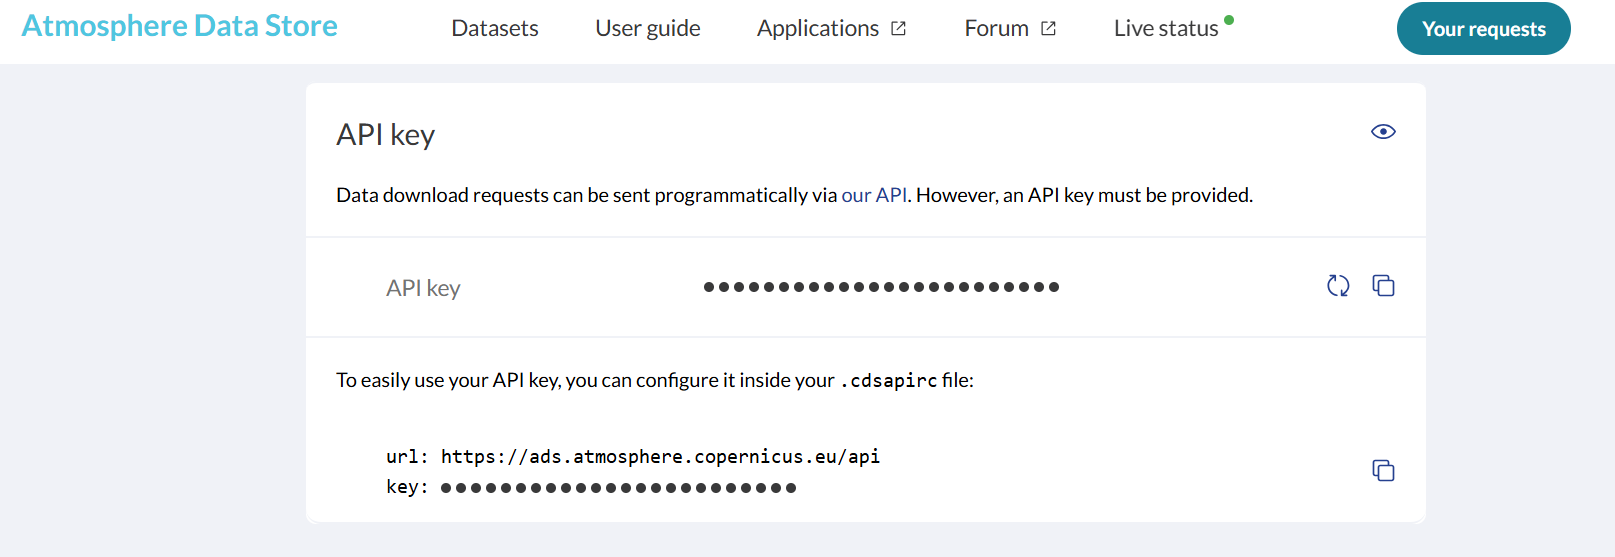

</details>


In [ ]:
#@title Set up the ADS API key (double-click to show the code)
if (DOWNLOAD_CAMS):
  if importlib.util.find_spec('cdsapi') is None:
    %pip install -q "cdsapi>=0.7.7"
  path = os.path.expanduser('~/.cdsapirc')
  # To replace an existing key, delete ~/.cdsapirc and run this cell again.
  if os.path.exists(path):
      print(f"Skipping: Configuration file already exists at {path}")
  else:
    from getpass import getpass
    api_key = getpass("Enter your Copernicus ADS API Key: ").strip()
    with open(path, 'w') as f:
        f.write(f"url: https://ads.atmosphere.copernicus.eu/api\nkey: {api_key}\n")
    print(f"\nSuccess! .cdsapirc has been created at {path}")

#### **3.2.2 Download the CAMS dust data**

CAMS zip files are stored in the output folder (`IRA_dust/` on Google Drive when `USE_GOOGLE_DRIVE` is True, otherwise in the project folder). Hourly NetCDF is extracted from those zips onto local disk only when `COMPUTE_CAMS_DAILY` is True, and the NetCDF is not copied to Drive.

<details>
<summary><b>More details</b></summary>

`DOWNLOAD_CAMS = True` sets `COMPUTE_CAMS_DAILY = True`. The cell first lists the zips already stored in the output folder: those are reused and only missing (or damaged) zips are downloaded. The daily mean itself depends on `EEA_temporal_flag`: a UTC grid for hourly EEA data, and a local-day mean at each station for daily EEA data.

When `COMPUTE_CAMS_DAILY` is False, this cell does not extract the zips. Later cells load the daily CAMS file saved by a previous run.

</details>


In [ ]:
#@title Download the CAMS dust data (double-click to show the code)
import importlib
import zipfile
import cams_data_to_eea_daily as cams_daily
importlib.reload(cams_daily)

VAR = "dust"
persistent_dir = gdrive_output_dir if USE_GOOGLE_DRIVE else project_dir

# Zips already in the output folder are not downloaded again; a damaged zip is downloaded again.
cams_plan = cams_daily.cams_download_plan(YEAR)
cams_missing = []
for cfg in cams_plan:
    zip_path = cams_daily.stored_cams_zip(persistent_dir, project_dir, VAR, cfg['filename'])
    if os.path.isfile(zip_path) and not zipfile.is_zipfile(zip_path):
        os.remove(zip_path)
        print(f'Damaged CAMS zip removed, it will be downloaded again: {zip_path}')
    if not os.path.isfile(zip_path):
        cams_missing.append(cfg['filename'])
print(f'CAMS zips already stored: {len(cams_plan) - len(cams_missing)} of {len(cams_plan)}'
      + (f"; missing: {', '.join(cams_missing)}" if cams_missing else ' (nothing to download)'))

if DOWNLOAD_CAMS and cams_missing:
    import site
    from importlib import reload
    reload(site)  # pick up a freshly installed cdsapi
    try:
        import cdsapi
        cdsapi.Client(quiet=True)
    except ImportError:
        print("cdsapi cannot be imported. Restart the session via: Runtime -> Restart session")
    except Exception as e:
        print(f"cdsapi is imported but failed to initialize: {e}")

if DOWNLOAD_CAMS or COMPUTE_CAMS_DAILY:
    # Zips stay in the output folder. Hourly NetCDF is extracted locally for this run only.
    cams_daily.download_and_extract_cams(
        project_dir,
        persistent_dir,
        YEAR,
        VAR,
        download=DOWNLOAD_CAMS and bool(cams_missing),
        extract=COMPUTE_CAMS_DAILY,
    )
else:
    print("COMPUTE_CAMS_DAILY is False. Zips are not extracted; the saved daily CAMS file is used later.")


<a name="4"></a>
## **4 - Data preparation**

This section filters the EEA observations, adds the station metadata and matches every station with the CAMS dust concentration of the same day.

### **4.1 Filter for validity and verification**

Only measurements with validity = 1 (valid) and verification = 1 or 2 (verified or preliminary verified) are kept. Negative values are also removed. 

<details>
<summary><b>EEA validity and verification codes</b></summary>

#### Validity

|ID     | Label                                       | Status    | Status Modified | Notation |
|-------|---------------------------------------------|-----------|-----------------|----------|
| -99   | Not valid due to station maintenance or calibration       | Valid           | 22.03.2013 | -99 |
| -1    | Not valid                                                 | Valid           | 22.03.2013 | -1  |
| 1     | Valid                                                     | Valid           | 22.03.2013 | 1   |
| 2     | Valid, but below detection limit measurement value given  | Valid           | 22.03.2013 | 2   |
| 3     | Valid, but below detection limit and number replaced by 0.5*detection limit | Valid           | 22.03.2013 | 3   |
| 4     | Valid (Ozone only) using CCQM.O3.2019                     | Valid           | 04.07.2024 | 4   |

#### Verification
| Id | Label                  | Status | Status Modified | Notation |
|----|------------------------|--------|-----------------|----------|
| 1  | Verified              | Valid  | 22.03.2013      | 1        |
| 2  | Preliminary verified  | Valid  | 22.03.2013      | 2        |
| 3  | Not verified          | Valid  | 22.03.2013      | 3        |

</details>

### **4.2 Filter temporal range**
Only stations with data for the selected year are kept. The pre-downloaded dataset also covers some days before and after the selected year, so that the reference window can also be computed for the first and last days of the year. EEA hourly data are provided in CET (UTC+1) and are converted to UTC. With `HOURLY_DAY_DEFINITION = 'local'` they are then shifted to the local time of each station (fixed offset from the `Timezone` label of `DataExtract.csv`, no daylight saving), so the daily mean covers 00:00–24:00 local time; with `'utc'` it covers 00:00–24:00 UTC.

<details>
<summary><b>Time zones of hourly and daily data</b></summary>

EEA hourly data are provided in CET (fixed UTC+1, no daylight-saving shift) and `eea_to_utc` converts them to UTC before the daily mean. EEA daily data are different: `Start` is the station's local time, taken from the `Timezone` label in `DataExtract.csv` (`UTC`, `UTC+01`, `UTC-04`, and so on). Those stamps are not passed through `eea_to_utc`. When `EEA_temporal_flag` is `day` and `COMPUTE_CAMS_DAILY` is True, section 4.5 averages CAMS (UTC) over the matching local day: local day D is the UTC window `[D 00:00 - offset, D+1 00:00 - offset)`.

</details>


In [ ]:
#@title Filter the EEA observations (double-click to show the code)
import gc

def eea_to_utc(series: pd.Series, source_tz: str = "CET") -> pd.Series:
    s = pd.to_datetime(series, errors="coerce")
    def _localize_if_naive(x):
        if pd.isna(x): return x
        return x.tz_localize("Etc/GMT-1") if x.tzinfo is None else x
    return s.apply(_localize_if_naive).dt.tz_convert("UTC")

# With USE_USER_OBSERVATIONS the daily table was already built in section 3.1.1.
LOAD_EEA_OBSERVATIONS = not LOAD_PARQUET_DATA and not USE_USER_OBSERVATIONS

if EEA_temporal_flag == 'hour' and LOAD_EEA_OBSERVATIONS:
    search_path = os.path.join(EEA_folder_path, "**/*.parquet")
    parquet_files = glob.glob(search_path, recursive=True)

    if parquet_files:
        needed_cols = ['Value', 'Validity', 'Verification', 'AggType', 'Start', 'Samplingpoint', 'Unit', 'Pollutant']

        dataframes = []
        for file in parquet_files:
            df_tmp = pd.read_parquet(file, columns=needed_cols)
            df_tmp['Value'] = pd.to_numeric(df_tmp['Value'], errors='coerce').astype('float32')
            df_tmp['Samplingpoint'] = df_tmp['Samplingpoint'].astype('category')
            df_tmp['Pollutant'] = df_tmp['Pollutant'].astype('category')
            dataframes.append(df_tmp)

        obs = pd.concat(dataframes, ignore_index=True)
        del dataframes
        gc.collect()

        obs['Validity'] = pd.to_numeric(obs['Validity'], errors='coerce').astype('int8')
        obs['Verification'] = pd.to_numeric(obs['Verification'], errors='coerce').astype('int8')
        obs['AggType'] = obs['AggType'].astype('category')
        obs['Start'] = eea_to_utc(obs['Start'])

        print(f"Observations Before filtering: {obs.shape[0]:,}")

        # Keep valid, verified, hourly, non-negative values
        mask = (obs['Validity'] == 1) & (obs['Verification'] < 3) & (obs['AggType'].str.lower() == 'hour') & (obs['Value'] >= 0)
        obs = obs.loc[mask].drop(columns=['Verification', 'AggType'], errors='ignore')

        if LOCAL_DAY:
            # Fixed offset of each station from the Timezone label of DataExtract.csv (no daylight saving).
            _meta_path = next((p for p in (os.path.join(OUTPUT_DIR, 'DataExtract.csv'),
                                           os.path.join(project_dir, 'DataExtract.csv'),
                                           os.path.join(project_dir, 'Data', 'DataExtract.csv'))
                               if os.path.exists(p)), None)
            _meta = cams_daily.combine_station_metadata(_meta_path, user_station_metadata)
            _keys = _meta['Air Quality Station EoI Code'].astype(str).str[:2] + '/' + _meta['Sampling Point Id'].astype(str)
            _tz = pd.Series(_meta['Timezone'].map(cams_daily.parse_tz_offset).to_numpy(), index=_keys)
            _tz = _tz[~_tz.index.duplicated()]
            _offset = obs['Samplingpoint'].astype(str).map(_tz)
            _no_tz = obs.loc[_offset.isna(), 'Samplingpoint'].astype(str).nunique()
            if _no_tz:
                # Same fallback as the CAMS local-day mean, so observations and CAMS keep the same day.
                print(f'{_no_tz} sampling point(s) have no time zone in DataExtract.csv and use UTC.')
            _local = obs['Start'].dt.tz_convert(None) + pd.to_timedelta(_offset.fillna(0).to_numpy(), unit='h')
            obs['day'] = _local.dt.floor('D')
        else:
            obs['day'] = obs['Start'].dt.floor('D')

        hourly_to_daily_eea = (
            obs.groupby(['Pollutant', 'day', 'Samplingpoint'], sort=True, observed=False)
            .agg(daily_mean=('Value', 'mean'), n_hours=('Value', 'count'), unit=('Unit', 'first'))
            .reset_index()
        )

        # Only keep full 24-hour days to ensure daily mean quality
        hourly_to_daily_eea = hourly_to_daily_eea[hourly_to_daily_eea['n_hours'] == 24]
        print(f"Final stations processed: {len(hourly_to_daily_eea['Samplingpoint'].unique())}")

        del obs
        gc.collect()
    else:
        print("Error: No parquet files found.")
elif EEA_temporal_flag == 'day' and LOAD_EEA_OBSERVATIONS:
    # Daily EEA timestamps are station local time. Do not call eea_to_utc:
    # that helper treats every naive stamp as fixed UTC+1 and would move a
    # UTC+2 station onto the previous UTC date.
    import importlib
    importlib.reload(cams_daily)
    hourly_to_daily_eea = cams_daily.load_and_filter_eea_daily(EEA_folder_path, temporal_flag='day')
    print(f"Final stations processed: {hourly_to_daily_eea['Samplingpoint'].nunique()}")


### **4.3 Load and merge station metadata**

The EEA observations identify each station only by its sampling point ID. The station metadata add the latitude, longitude, altitude and time zone of each station, which are needed to match the stations with the CAMS dust data.

Before running this step, download the metadata file manually:

1.   Open the EEA Air Quality Viewer and download the station metadata as a CSV file (https://discomap.eea.europa.eu/App/AQViewer/index.html?fqn=Airquality_Dissem.b2g.measurements).
2.   Name the file `DataExtract.csv`.
3.   Save it in your output folder (`CAMS_Tool_output` on Google Drive, or the project folder when `USE_GOOGLE_DRIVE = False`).


In [ ]:
#@title Load and merge station metadata (double-click to show the code)
import calendar
import util

# Inject calendar into the util module namespace to resolve NameError
util.calendar = calendar

if EEA_temporal_flag in ('hour', 'day') and not(LOAD_PARQUET_DATA):
    df_processed = filter_daily_by_coverage(hourly_to_daily_eea, reference_year=YEAR, min_pct=Station_Temporal_coverage, keep_coverage_columns=False)

    # Report the stations removed by the coverage filter, with their coverage in YEAR.
    _days = pd.to_datetime(hourly_to_daily_eea['day'], utc=True, errors='coerce').dt.floor('D')
    _ids = hourly_to_daily_eea['Samplingpoint'].astype(str)
    _in_year = _days.dt.year == YEAR
    _coverage = _days[_in_year].groupby(_ids[_in_year]).nunique() / (366 if calendar.isleap(YEAR) else 365) * 100
    _removed = sorted(set(_ids) - set(df_processed['Samplingpoint'].astype(str)))
    print(f'Coverage filter (at least {Station_Temporal_coverage}% of the days of {YEAR} with valid data): '
          f'{_ids.nunique() - len(_removed)} of {_ids.nunique()} stations kept, {len(_removed)} removed.')
    if _removed:
        display(_coverage.reindex(_removed).fillna(0).round(1).sort_values().rename(f'Coverage {YEAR} (%)').to_frame())

    # Flag exceedance days with concentration above threshold
    df_processed['Exceedance'] = df_processed['daily_mean'] > POLLUTANT_daily_threshold

    print(f'Total stations found in dataset: {len(df_processed["Samplingpoint"].unique())}')

    _metadata_candidates = [
        os.path.join(OUTPUT_DIR, 'DataExtract.csv'),
        os.path.join(project_dir, 'DataExtract.csv'),
        os.path.join(project_dir, 'Data', 'DataExtract.csv'),
    ]
    metadata_path = next((p for p in _metadata_candidates if os.path.exists(p)), None)

    if metadata_path or user_station_metadata is not None:
        # Stations from the user stations file (section 3.1.1) come first and replace DataExtract.csv rows.
        metadata = cams_daily.combine_station_metadata(metadata_path, user_station_metadata)
        metadata['Samplingpoint'] = metadata['Air Quality Station EoI Code'].str[:2] + '/' + metadata['Sampling Point Id']
        stations_geo = metadata[['Samplingpoint', 'Longitude', 'Latitude', 'Altitude', 'Timezone']].drop_duplicates(subset=['Samplingpoint'])
        df_processed = df_processed.merge(stations_geo, on='Samplingpoint', how='left')
        print(f"Metadata successfully merged from: {metadata_path or 'the user stations file'}")
        if USE_USER_OBSERVATIONS:
            no_coords = df_processed.loc[df_processed['Latitude'].isna(), 'Samplingpoint'].unique()
            if len(no_coords):
                print(f'{len(no_coords)} station(s) without coordinates are dropped; add them to {USER_STATIONS_FILE}: '
                      f'{list(no_coords)[:10]}')
                df_processed = df_processed.dropna(subset=['Latitude', 'Longitude'])
    else:
        print(f"Warning: DataExtract.csv not found in {_metadata_candidates}. Skipping spatial merge.")


In [ ]:
#@title Old metadata merge (not used) (double-click to show the code)
# # Re-run the metadata merge with the local file
# if os.path.exists(local_metadata):
#     metadata = pd.read_csv(local_metadata, low_memory=False)
#     metadata['Samplingpoint'] = metadata['Air Quality Station EoI Code'].str[:2] + '/' + metadata['Sampling Point Id']
#     stations_geo = metadata[['Samplingpoint', 'Longitude', 'Latitude', 'Altitude', 'Timezone']].drop_duplicates(subset=['Samplingpoint'])

#     # Merge onto the processed dataframe (using the 0-pct version created previously)
#     df_processed = df_processed.merge(stations_geo, on='Samplingpoint', how='left')
#     print(f"Metadata successfully merged. Valid stations with coords: {df_processed['Longitude'].notna().sum()}")
# else:
#     print("Local metadata file missing, please check if the copy step succeeded.")

### **4.4 Compute daily mean CAMS dust**

The cell below converts the hourly CAMS dust data downloaded in Section 3 into daily mean dust concentrations over the whole CAMS domain.

*   When `COMPUTE_CAMS_DAILY` = True: the monthly NetCDF files for the selected year are combined into one hourly dataset and averaged to daily means. Days are defined in UTC, matching the daily means computed from the EEA observations in 4.1. The result is saved as `cams_dust_{YEAR}_daily_mean.nc` in the `IRA_dust` folder.
*   When `COMPUTE_CAMS_DAILY` = False: the daily mean file saved in a previous run is loaded instead.

<details>
<summary><b>Memory note and daily EEA data</b></summary>

**Memory note:** Computing the daily means for the full CAMS domain may exceed the memory available on Google Colab. If so, run this step once on a local machine or an HPC system and copy the saved daily mean file to your output folder.

This full-domain UTC grid is only used for hourly data with `HOURLY_DAY_DEFINITION = 'utc'`. For daily data, or hourly data with `'local'`, it is skipped. Local-day means are built in section 4.5, one UTC day at a time and only at station coordinates, then cached as Parquet under `IRA_dust/` on Google Drive (or in the project folder). A later run reuses those files when they are already there.

</details>


In [ ]:
#@title Compute daily mean CAMS dust (double-click to show the code)
##############################################
##############cams data for hourly############
##############################################
if not LOCAL_DAY and not(LOAD_PARQUET_DATA):
    # Target output file path
    if USE_GOOGLE_DRIVE:
        daily_cams_path = os.path.join(gdrive_output_dir, f'IRA_{VAR}/cams_dust_{YEAR}_daily_mean.nc')
    else:
        daily_cams_path = os.path.join(project_dir, f"IRA_{VAR}/cams_dust_{YEAR}_daily_mean.nc")

    # Check if we should compute or just load
    if COMPUTE_CAMS_DAILY:
        netcdf_files = np.sort(glob.glob(os.path.join(project_dir, f'IRA_{VAR}/cams.eaq.ira.ENSa.dust*%s*.nc'%(YEAR))))
        print(f"Found {len(netcdf_files)} source files for processing.")

        datasets = []
        for f in netcdf_files:
            try:
                # Use chunks to enable dask-backed lazy loading to save RAM
                ds = xr.open_dataset(f, chunks={'time': 24, 'lat': 100, 'lon': 100})
                datasets.append(ds)
            except Exception as e:
                print(f"Error opening {f}: {e}")

        if datasets:
            print("Aligning and combining datasets...")
            master_lat = datasets[0].lat
            master_lon = datasets[0].lon

            aligned_ds = []
            for ds in datasets:
                if not (ds.lat.equals(master_lat) and ds.lon.equals(master_lon)):
                    ds = ds.interp(lat=master_lat, lon=master_lon, method="nearest")
                aligned_ds.append(ds)

            cams = xr.concat(aligned_ds, dim='time').sortby('time')

            print("Resampling to daily mean...")
            from dask.diagnostics import ProgressBar
            with ProgressBar():
                daily_cams = cams.resample(time='1D').mean(keep_attrs=False).compute()

            # Strip attributes to prevent UnicodeEncodeError during save
            daily_cams.attrs = {}
            for var in daily_cams.variables:
                daily_cams[var].attrs = {}

            os.makedirs(os.path.dirname(daily_cams_path), exist_ok=True)
            print(f"Saving processed file to {daily_cams_path}...")
            daily_cams.to_netcdf(daily_cams_path)
            print(f"Saved daily means successfully.")
            cams.close()
        else:
            print("No source datasets were found to process.")
    else:
        if os.path.exists(daily_cams_path):
            print(f"Loading existing daily mean file from: {daily_cams_path}")
            # Use chunks here even when loading the processed file
            daily_cams = xr.open_mfdataset(daily_cams_path, chunks={'time': 'auto'})
            print(f'cams dust unit: {daily_cams["dust"].attrs.get("unit", "N/A")}')
            print(f'cams dust dimension: {daily_cams["dust"].dims}')
        else:
            print(f"Daily mean file not found and COMPUTE_CAMS_DAILY is False.")
elif LOCAL_DAY and not(LOAD_PARQUET_DATA):
    print(
        "Skipping the UTC daily CAMS grid. Section 4.5 builds one local-day "
        "mean per station from hourly CAMS, in chunks, and caches it on Drive."
    )


### **4.5 Match CAMS dust to each station**

Daily CAMS dust concentrations are interpolated to each station location. The result is a single table with one row per station and day, combining the measured daily mean, the exceedance flag and the CAMS dust concentration.

<details>
<summary><b>How the matching works</b></summary>

With UTC days (hourly data, `HOURLY_DAY_DEFINITION = 'utc'`) the UTC daily grid is interpolated with `add_cams_daily_dust_by_station`. With local days (daily data, or hourly data with `'local'`) the notebook calls `add_cams_local_daily_dust` in `cams_data_to_eea_daily.py`. That joins on the local calendar date, not on the nearest UTC day. `COMPUTE_CAMS_DAILY` decides whether that product is rebuilt; the EEA time resolution decides which average is built. The dust flag, background median, corrected concentration, station summary and plots below are unchanged.

</details>


In [ ]:
#@title Match CAMS dust to each station (double-click to show the code)
if not LOCAL_DAY and not(LOAD_PARQUET_DATA):
    # cams: your xarray.Dataset with hourly dust
    # df_processed: your daily DataFrame
    print('Filtering stations outside CAMS domain and interpolating CAMS data...')

    # 1. Get CAMS spatial bounds
    lat_min, lat_max = daily_cams.lat.min().item(), daily_cams.lat.max().item()
    lon_min, lon_max = daily_cams.lon.min().item(), daily_cams.lon.max().item()

    # 2. Filter df_processed to only include stations within the CAMS domain
    # This prevents interpolation errors and ensures data consistency
    stations_before = len(df_processed['Samplingpoint'].unique())
    df_processed = df_processed[
        (df_processed['Latitude'] >= lat_min) & (df_processed['Latitude'] <= lat_max) &
        (df_processed['Longitude'] >= lon_min) & (df_processed['Longitude'] <= lon_max)
    ].copy()
    stations_after = len(df_processed['Samplingpoint'].unique())

    print(f"Stations filtered: {stations_before - stations_after} removed, {stations_after} remain within CAMS domain.")

    # 3. Interpolate cams data to the remaining station locations
    df = add_cams_daily_dust_by_station(
        cams_ds=daily_cams,
        df=df_processed,
        var_name='dust',
        time_col='day',
        lat_col='Latitude',
        lon_col='Longitude',
        station_col='Samplingpoint',
        spatial_method='linear'
    )
    display(df.head())
elif LOCAL_DAY and not(LOAD_PARQUET_DATA):
    import importlib
    import cams_data_to_eea_daily as cams_daily
    importlib.reload(cams_daily)
    cams_cache_dir = gdrive_output_dir if USE_GOOGLE_DRIVE else project_dir
    nc_files = cams_daily.list_cams_netcdf(project_dir, cams_cache_dir, VAR, YEAR)
    print(f"CAMS files for local-day means: {len(nc_files)}")
    print("Building CAMS daily dust on each station local day (one UTC day of the grid at a time).")
    df = cams_daily.add_cams_local_daily_dust(
        nc_files,
        df_processed,
        var_name=VAR,
        buffer=0.2,
        cache_dir=cams_cache_dir,
        reuse_cache=True,
        recompute_daily=bool(COMPUTE_CAMS_DAILY),
        min_hours=18,
        time_col='day',
        year=YEAR,
    )
    display(df.head())


<a name="5"></a>
## **5 - Station pairing**

The natural dust load is quantified at a reference station that represents the regional background. Before the deduction in section 7, every station is therefore classified and linked to a suitable reference station. The default pairing follows the rules below; it can be reviewed on the map (5.2) and edited on the map or as a CSV file (5.3).

### **5.1 Station classification and default pairing**

Stations are classified from the `Air Quality Station Type` and `Air Quality Station Area` columns of `DataExtract.csv`:

| Class | Rule |
|---|---|
| **RB** regional background | rural* area and background type |
| **UB** urban background | urban or suburban area and background type |
| **TH** hotspot | traffic or industrial type |

Each non-RB station is paired with the nearest RB station of the same country (`PAIR_SAME_COUNTRY`) within `MAX_RB_DISTANCE_KM` and `MAX_RB_ALTITUDE_DIFF_M`. Each station has at most one reference. A TH station without a suitable RB is paired with the nearest UB station within `MAX_UB_DISTANCE_KM`; without RB or UB it gets no reference. An RB station is its own reference. The method follows from the pairing:

<details>
<summary><b>Method per pairing and pairing options</b></summary>

| Method | When | Natural load used |
|---|---|---|
| `option1` | suitable RB | net load at the paired RB |
| `option2` | UB without suitable RB | self-calibration at the station |
| `option2_ub_paired` | TH without suitable RB | Option 2 load of the paired UB |
| `none` | no valid reference | nothing is subtracted |

The default pairing is saved as `station_pairing_default.csv`. With `USE_USER_PAIRING = True` the edited `station_pairing_user.csv` is applied on top of it. The deduction in section 7 always reads the current pairing table, so edits made below are used the next time section 7 runs.

With `PAIRING_MODE = 'none'` no pairing is done: RB stations use `option1` on their own data (±15-day window) and all other stations (UB, TH and unknown) use `option2` self-calibration (±3-day episode window). Nothing is written to the pairing CSV files.

</details>


In [ ]:
#@title Classify and pair the stations (double-click to show the code)
pairing_dir = gdrive_output_dir if USE_GOOGLE_DRIVE else project_dir
pairing_user_path = os.path.join(pairing_dir, USER_PAIRING_FILE)
pairing_default_path = os.path.join(pairing_dir, pr.DEFAULT_PAIRING_FILENAME)
country_tag = '_'.join(sorted(Countries))


def deduction_parquet_for(temporal_flag):
    """Deduction Parquet of this selection; the country codes are part of the name."""
    # Hourly data on the local day get their own name, so they never mix with older UTC-day results.
    local_hourly = temporal_flag == 'hour' and HOURLY_DAY_DEFINITION == 'local'
    suffix = '_localday' if local_hourly else ''
    path = os.path.join(
        pairing_dir, f'CAMS_dust_{POLLUTANT}_deduction_{dataset}_{temporal_flag}_{YEAR}_{country_tag}{suffix}.parquet')
    if LOAD_PARQUET_DATA and not os.path.exists(path) and not local_hourly:
        # Files saved by earlier versions have no country codes in the name (or end in _MA6).
        older = cams_daily.find_deduction_parquet(pairing_dir, POLLUTANT, dataset, temporal_flag, YEAR)
        if os.path.exists(older):
            print(f'{os.path.basename(path)} not found; using {os.path.basename(older)}, '
                  'saved without country codes in the name (it may contain other countries).')
            return older
    return path


deduction_parquet = deduction_parquet_for(EEA_temporal_flag)

_metadata_candidates = [
    os.path.join(pairing_dir, 'DataExtract.csv'),
    os.path.join(project_dir, 'DataExtract.csv'),
    os.path.join(project_dir, 'Data', 'DataExtract.csv'),
]
pairing_metadata_path = next((p for p in _metadata_candidates if os.path.exists(p)), None)
if pairing_metadata_path is None and user_station_metadata is None:
    raise FileNotFoundError(f'DataExtract.csv not found in {_metadata_candidates}')

# Only stations with data can be references: this run's stations, or those in the saved Parquet.
if not LOAD_PARQUET_DATA:
    pairing_station_ids = df['Samplingpoint'].astype(str).unique()
elif os.path.exists(deduction_parquet):
    pairing_station_ids = pd.read_parquet(deduction_parquet, columns=['Samplingpoint'])['Samplingpoint'].astype(str).unique()
else:
    pairing_station_ids = None
    print(f'{deduction_parquet} not found; pairing all stations of the selected countries.')

# User stations (section 3.1.1) are added to DataExtract.csv and replace rows with the same id.
pairing_metadata = cams_daily.combine_station_metadata(pairing_metadata_path, user_station_metadata)
stations = pr.build_station_table(
    pairing_metadata, pollutant=POLLUTANT, station_ids=pairing_station_ids, countries=Countries
)

if PAIRING_MODE == 'none':
    # No pairing: RB stations use Option 1 on their own data, all others Option 2 self-calibration.
    default_pairing = pr.no_pairing(stations)
    station_pairing, pairing_report = default_pairing.copy(), None
    print(f'{len(stations)} stations classified; no pairing '
          f'(RB: Option 1 ±{OPTION1_HALF_WINDOW} d, others: Option 2 ±{OPTION2_HALF_WINDOW} d).')
else:
    default_pairing = pr.default_pairing(stations, PAIRING_LIMITS)
    pr.export_pairing_csv(default_pairing, pairing_default_path)
    print(f'{len(stations)} stations classified; default pairing saved to {pairing_default_path}')
    n_unknown = int((stations['class'] == 'unknown').sum())
    if n_unknown:
        print(f'{n_unknown} station(s) have an unknown area/type and get method none.')

    station_pairing, pairing_report = pr.load_pairing(
        stations, default_pairing, pairing_user_path,
        use_user_pairing=USE_USER_PAIRING, limits=PAIRING_LIMITS,
    )
    if pairing_report is not None:
        print(f'Using {pairing_user_path}')
        print(pairing_report.summary())
        display(pairing_report.changes)

# The deduction in section 7 reads pairing_session.table.
pairing_session = pv.PairingSession(
    stations, default_pairing, station_pairing,
    limits=PAIRING_LIMITS, autosave_path=pairing_user_path if PAIRING_MODE == 'default' else None,
)
display(pr.method_counts(pairing_session.table))
display(pairing_session.table.head())


### **5.2 Pairing map and editor**

The interactive map shows every station coloured by class (green RB, blue UB, red TH). Green lines join a station to its RB reference, thinner orange lines join a TH station to its UB reference. Grey markers have method `none`: no natural contribution can be computed (e.g. a TH station without a suitable RB or UB, or an unknown class). A UB station without RB is not grey: it uses Option 2 self-calibration. Hover a station to see its id, name, class, area, altitude, paired stations, distance, altitude difference, method and whether the pairing is default or manual. Use the country and class filters to reduce the map.

<details>
<summary><b>How to edit a pairing and map options</b></summary>

To change a pairing, click a station (or type its id or name), choose the paired RB and/or UB from the candidates (sorted by distance, with distance and altitude difference), or choose *none / force Option 2*. **Save** marks the station as manual, recomputes the distances and the method, writes `station_pairing_user.csv` to the output folder and redraws the map. **Reset station** and **Reset all** return to the default pairing.

If the widgets do not work in your environment, use the static map in the next cell and the CSV route in section 5.3.

With `CLICKABLE_PAIRING_MAP = True` (default) the map is clickable; it needs Plotly 6 or newer, which the first cell installs (restart the kernel if Plotly 5 was already imported). Set it to `False` to draw the map as a static image that is redrawn after each change.

</details>


In [ ]:
###################Edit here#########################
CLICKABLE_PAIRING_MAP = True   # False: static image instead of the clickable map (needs Plotly 6+)
###################Stop here#########################

In [ ]:
#@title Pairing map and editor (double-click to show the code)
pairing_widget = pv.pairing_app(pairing_session, countries=Countries, clickable_map=CLICKABLE_PAIRING_MAP)
display(pairing_widget)

In [ ]:
###################Edit here#########################
pairing_countries = Countries      # e.g. ['ES']
pairing_classes   = ['RB', 'UB', 'TH']
###################Stop here#########################

In [ ]:
#@title Static pairing map (double-click to show the code)
fig, ax = pv.plot_station_pairing_static(pairing_session.table, pairing_countries, pairing_classes)
plt.show()

### **5.3 Edit the pairing as a CSV file**

1. Run the first cell below. It writes the current pairing to `station_pairing_user.csv` in the output folder and, in Colab, downloads it.
2. Open the file (e.g. in Excel) and change only `paired_rb_id`, `paired_ub_id`, `method` (`option1`, `option2`, `option2_ub_paired`, `none`, or empty to derive it from the pairing; `option2` for a TH station is a manual exception to the guidance) or `comment`. Other columns are recomputed.
3. Upload it with the second cell (`UPLOAD_PAIRING_CSV = True` in Colab) or save it back as `station_pairing_user.csv` in the output folder, then run the second cell.

<details>
<summary><b>Checks when the file is loaded</b></summary>

On loading, every id must exist, a paired RB must be an RB station and a paired UB a UB station; otherwise the file is rejected with a list of errors. Pairs beyond the distance or altitude limits only give a warning. Changed stations are marked `source = manual` and the changes against the default pairing are listed. The map above is redrawn. Set `USE_USER_PAIRING = True` to start from this file in later sessions.

</details>


In [ ]:
#@title Export the pairing to CSV (double-click to show the code)
pairing_session.export_csv(pairing_user_path)
print(f'Pairing table ({len(pairing_session.table)} stations) written to {pairing_user_path}')
pv.download_file(pairing_user_path)

In [ ]:
###################Edit here#########################
# Set True in Colab to choose the edited CSV on your computer; otherwise place it in the output folder.
UPLOAD_PAIRING_CSV = False
###################Stop here#########################

In [ ]:
#@title Load the edited pairing CSV (double-click to show the code)
if UPLOAD_PAIRING_CSV:
    pv.upload_pairing_csv(pairing_user_path)

if os.path.exists(pairing_user_path):
    try:
        pairing_report = pairing_session.load_csv(pairing_user_path)
        print(pairing_report.summary())
        display(pairing_report.changes)
        display(pr.method_counts(pairing_session.table))
    except pr.PairingValidationError as exc:
        print(exc)
        print('The pairing was not changed. Fix the CSV and run this cell again.')
else:
    print(f'No edited pairing found at {pairing_user_path}.')

<a name="6"></a>
## **6 - Flag dust days with CAMS data**

Two flags are assigned to every station and day:

*   Dust day (`dust_flag`, stored as `cams_dust_flag` in section 7): the CAMS dust concentration at the station is above `CAMS_dust_threshold` (default 5 µg/m³). These are the natural-event days.
*   Exceedance (`Exceedance`): the measured daily mean is above the daily limit value, `POLLUTANT_daily_threshold`.

The natural contribution is quantified and subtracted on **every** dust day in Section 7, whether or not there is an exceedance.


In [ ]:
#@title Flag dust days with CAMS data (double-click to show the code)
if not(LOAD_PARQUET_DATA):
  # Flag dust days for cams dust > threshold selected
  df['dust_flag'] = df['cams_dust'] > CAMS_dust_threshold
  df['Exceedance'] = df['daily_mean'] > POLLUTANT_daily_threshold

  print('Below shows the new table with dust flag and Exceedance')
  display(df.head())

  # Inspect the rows with negative values to see which stations/dates are problematic
  negative_rows = df[df['daily_mean'] < 0]
  print(f"Number of rows with negative daily_mean: {len(negative_rows)}")
  if not negative_rows.empty:
      display(negative_rows.sort_values('daily_mean').head(10))
  else:
      print("No negative values found in the current 'df' variable.")

<a name="7"></a>
## **7 - Calculate the dust contribution**

The natural contribution is quantified with the method set in the pairing table (section 5). Event days (CAMS dust days) are excluded from every reference window.

The contribution is subtracted on every event day, with or without an exceedance; other days get 0. Adjusted value = measured − contribution (never below 0). A dust day is a quantified dust day (`quantified_dust_day`) only when the quantified contribution is > 0.

<details>
<summary><b>Option 1 – regional background (preferred)</b></summary>

At the paired RB station, for each event day *d*, the reference is the `REFERENCE_PERCENTILE` (50th) percentile of the days *d*−15 … *d*+15 that are not event days. The net natural load at the RB is max(measured RB(*d*) − reference, 0). The same daily load is subtracted at every station paired to that RB, including the RB itself.

</details>

<details>
<summary><b>Option 2 – self-calibration (UB without suitable RB)</b></summary>

At the station itself, window *d*−3 … *d*+3 without event days. For a multi-day episode, the 3 days before its start and the 3 days after its end (without event days) are the reference for every day of the episode.

</details>

<details>
<summary><b>TH stations and insufficient reference</b></summary>

**TH stations** do not self-calibrate: they use the Option 1 load of their RB or, without a suitable RB, the Option 2 load of their paired UB. A TH station can be set to `option2` by hand (map editor or CSV in section 5) as a manual exception to the guidance; it then self-calibrates like a UB.

If fewer than `MIN_REFERENCE_DAYS_OPTION1` / `MIN_REFERENCE_DAYS_OPTION2` valid reference days are available, the day is flagged `insufficient_reference` and nothing is subtracted.

The calculation uses the whole downloaded period (from 14 December of the previous year) and then keeps the selected year.

</details>


In [ ]:
#@title Calculate the dust contribution (double-click to show the code)
import gc

if not(LOAD_PARQUET_DATA):
  df_target_year = nc.run_natural_deduction(
      df,
      pairing_session.table,
      YEAR,
      pollutant=POLLUTANT,
      dust_threshold=CAMS_dust_threshold,
      params=METHOD_PARAMS,
      limits=LIMITS,
  )
  gc.collect()
  display(df_target_year[nc.NEW_COLUMNS].head())

The cell below summarises the event days per class and method.

<details>
<summary><b>New columns in the daily table</b></summary>

New columns in the daily table: `station_class`, `method`, `reference_station_id`, `reference_value` (percentile reference at the reference station), `natural_contribution`, `cams_dust_flag`, `quantified_dust_day`, `adjusted_value`, `insufficient_reference` and `pairing_source`. The previous column names are kept for the plots: `dust_flag` = `cams_dust_flag`, `pollutant_median` = `reference_value`, `Dust_contribution` = `natural_contribution`, `corrected_pollutant` = `adjusted_value`.

</details>


In [ ]:
#@title Dust days per class and method (double-click to show the code)
if not(LOAD_PARQUET_DATA):
  event_days = df_target_year[df_target_year['cams_dust_flag']]
  display(
      event_days.groupby(['station_class', 'method'], observed=True)
      .agg(
          stations=('Samplingpoint', 'nunique'),
          cams_dust_days=('cams_dust_flag', 'sum'),
          quantified_dust_days=('quantified_dust_day', 'sum'),
          insufficient_reference=('insufficient_reference', 'sum'),
          mean_contribution=('natural_contribution', 'mean'),
      )
  )

<details>
<summary><b>Alternative method of using CAMS dust only (not used)</b></summary>

Corrected Dust = $(1+ \frac{Observed PM_{10}-Reanalysis PM_{10}}{Reanalysis PM_{10}})\ x\ Reanalysis Dust$

</details>


In [ ]:
#@title Alternative method (not used) (double-click to show the code)
# obs_2024 = df[(df['day'] >= '2024-01-01') & (df['day'] < '2025-01-01')].copy()
# # Ratio of (Observed Mean / CAMS Modeled PM10) * CAMS Dust
# calculation = (obs_2024['daily_mean'] / obs_2024['cams_pm10']) * obs_2024['cams_dust']

# # Apply only where dust_flag is True, otherwise keep original daily_mean (or NaN)
# obs_2024['dust'] = np.where(
#     (obs_2024['dust_flag'] == True) & (obs_2024['Exceedance'] == True),
#     calculation,
#     obs_2024['daily_mean'] # Or np.nan if you only want dust values
# )
# obs_2024['corrected_PM10'] = obs_2024['daily_mean'].astype(float)
# mask = obs_2024['dust_flag'] & obs_2024['Exceedance']
# obs_2024.loc[mask, 'corrected_PM10'] = obs_2024.loc[mask, 'daily_mean'] - obs_2024.loc[mask, 'dust']

### **7.1 Check dust days without a natural contribution and insufficient references**

When the measurement at the reference station is not above its reference, the net load is 0 and the CAMS dust day is not a quantified dust day (`quantified_dust_day = False`). This can happen because CAMS flags dust that does not reach the ground, or because strong winds during a dust event lower local PM. Days without enough valid reference days are flagged `insufficient_reference` and keep the measured value.


In [ ]:
#@title Check dust days without a natural contribution (double-click to show the code)
if not(LOAD_PARQUET_DATA):
  cams_days = int(df_target_year['cams_dust_flag'].sum())
  quantified = int(df_target_year['quantified_dust_day'].sum())
  insufficient = int(df_target_year['insufficient_reference'].sum())
  print(f'CAMS dust days: {cams_days}, quantified: {quantified}, '
        f'without contribution: {cams_days - quantified - insufficient}, insufficient reference: {insufficient}')
  print(f"Negative contributions: {int((df_target_year['natural_contribution'] < 0).sum())}")

<a name="8"></a>
## **8 - Save or load results**

*   First run (`LOAD_PARQUET_DATA` = False): the daily results for all stations are saved as a Parquet file named after the selected settings (e.g. `CAMS_dust_PM10_deduction_E2a_hour_2025_ES_PT.parquet`, with the country codes of `Countries`) in the output folder.
*   Later runs (`LOAD_PARQUET_DATA` = True): Sections 3 to 7 are skipped and the saved file is loaded directly, without downloading or processing the data again. Files saved by earlier versions (without country codes, or ending in `_MA6.parquet`) are still found, with a warning. With `REAPPLY_PAIRING_ON_LOAD = True` the deduction is recomputed on the loaded table with the current pairing (section 5), so pairing edits are used without reprocessing CAMS. The saved file only covers the selected year, so the first and last days of the year then have a shorter reference window.

From here on, the notebook works the same way whether the results were just computed or loaded from file.


In [ ]:
#@title Save or load the results (double-click to show the code)
import pyarrow as pa
import pyarrow.parquet as pq

# deduction_parquet is set in section 5.
if not LOAD_PARQUET_DATA:
    table = pa.Table.from_pandas(df_target_year)
    pqwriter = pq.ParquetWriter(deduction_parquet, table.schema, use_dictionary=True, compression='snappy')
    pqwriter.write_table(table)
    pqwriter.close()
    print(f'save to {deduction_parquet}')
else:
    print(f'open {deduction_parquet}')
    df_target_year = pd.read_parquet(deduction_parquet)
    if REAPPLY_PAIRING_ON_LOAD:
        df_target_year = nc.compute_natural_contribution(
            df_target_year,
            pairing_session.table,
            dust_threshold=CAMS_dust_threshold,
            params=METHOD_PARAMS,
            daily_limit=POLLUTANT_daily_threshold,
        )
        print('Deduction recomputed with the current pairing.')

### **8.1 Station summary**

The adjusted daily series is summarised per station for the selected year. Exceedances and annual means are recalculated from the daily values with and without the natural contribution, so the adjusted annual mean includes the subtraction on every dust day.

<details>
<summary><b>Columns of the station summary</b></summary>

| Column | Description |
|:---|:---|
| **station_class**, **method**, **reference_station_id**, **pairing_source** | Class, method and reference station used, and whether the pairing is default or manual |
| **cams_dust_days**, **quantified_dust_days**, **insufficient_reference_days** | CAMS dust days, dust days with a contribution > 0, and days without enough reference data |
| **exceedances_measured** / **exceedances_adjusted** | Days above the daily limit before / after subtracting the natural contribution |
| **exceedances_natural** | Exceedances attributed to natural sources |
| **annual_mean_measured** / **annual_mean_adjusted** | Annual mean before / after subtraction |
| **annual_limit_exceeded_measured** / **_adjusted** | Annual mean above the annual limit value |

The previous columns (`Exceedance_days`, `Dust_exceedance_days`, `NonDust_exceedance`, `Average_pollutant`, `Average_pollutant_dust_removed`) are kept with the same meaning for the maps in section 9.

</details>


In [ ]:
#@title Station summary (double-click to show the code)
if 'adjusted_value' in df_target_year.columns:
    station_table = nc.station_indicators(
        df_target_year,
        daily_limit=POLLUTANT_daily_threshold,
        annual_limit=POLLUTANT_annual_threshold,
    )
else:
    # Parquet from an earlier version, loaded with REAPPLY_PAIRING_ON_LOAD = False.
    station_table = cams_daily.station_summary_table(df_target_year, POLLUTANT_daily_threshold)
display(station_table.head())

### **8.2 Export to CSV**

The station summary is saved as a CSV file in the output folder, e.g. `ES_PT_station_annual_PM10_E2a_hour_2025.csv`.


In [ ]:
#@title Export the station table (double-click to show the code)
key = '_'.join(sorted(Countries))

# Determine the output path for CSV files
if USE_GOOGLE_DRIVE:
    csv_output_dir = gdrive_output_dir
else:
    csv_output_dir = project_dir

station_table.to_csv(os.path.join(csv_output_dir, f'{key}_station_annual_{POLLUTANT}_{dataset}_{EEA_temporal_flag}_{YEAR}.csv'))

#### **8.2.1 Optional: model-specific dust threshold**

`CAMS_dust_threshold` stays a parameter. The cell below recomputes the deduction for a list of thresholds and, per country (or region), reports the share of CAMS dust days on which the quantified contribution is > 0. The suggested threshold is the lowest one from which every higher threshold has at least `SWEEP_MIN_SHARE` quantified dust days. Each threshold is a full recomputation, so this can take several minutes for many countries.


In [ ]:
###################Edit here#########################
RUN_THRESHOLD_SWEEP = False
SWEEP_THRESHOLDS    = [2, 3, 4, 5, 6, 7, 8, 10]   # µg/m3
SWEEP_GROUP         = 'country'                   # or a region column present in the table
SWEEP_MIN_SHARE     = 0.9                         # share of CAMS dust days with contribution > 0
SWEEP_MIN_DAYS      = 10                          # ignore thresholds with fewer CAMS dust days
###################Stop here#########################

In [ ]:
#@title Run the threshold sweep (double-click to show the code)

if RUN_THRESHOLD_SWEEP:
    import dust_threshold_sensitivity as sens
    sweep_input = df if not LOAD_PARQUET_DATA else df_target_year
    parts = []
    for threshold in SWEEP_THRESHOLDS:
        frame = nc.compute_natural_contribution(
            sweep_input, pairing_session.table, dust_threshold=threshold,
            params=METHOD_PARAMS, daily_limit=POLLUTANT_daily_threshold,
        )
        parts.append(sens.contribution_consistency({float(threshold): frame}, group_col=SWEEP_GROUP))
        del frame
        gc.collect()
    threshold_consistency = pd.concat(parts, ignore_index=True)
    threshold_suggestion = sens.lowest_consistent_threshold(
        threshold_consistency, group_col=SWEEP_GROUP,
        min_share=SWEEP_MIN_SHARE, min_days=SWEEP_MIN_DAYS,
    )
    display(threshold_consistency)
    display(threshold_suggestion)


<details>
<summary><b>Plots of the threshold sweep</b></summary>

Run the cell above with `RUN_THRESHOLD_SWEEP = True` first.

1. **Heatmap**: share of CAMS dust days with a quantified contribution > 0, per country and threshold. Cells with fewer than `SWEEP_MIN_DAYS` dust days are hatched (not used for the suggestion); the black frame marks the suggested threshold.
2. **Per country**: share quantified (line, left axis) and number of CAMS dust days (bars, right axis) against the threshold, with the `SWEEP_MIN_SHARE` line and the suggested threshold.
3. **Suggested threshold per country**: grey bars mean no threshold of the list reaches `SWEEP_MIN_SHARE`.

With `SAVE_SWEEP_PLOTS = True` the figures are saved as PNG in the output folder.

</details>


In [ ]:
###################Edit here#########################
SAVE_SWEEP_PLOTS = False
SWEEP_PLOT_COLS  = 5      # countries per row in the per-country plot
###################Stop here#########################

In [ ]:
#@title Plot the threshold sweep (double-click to show the code)
import math
import matplotlib.patches as mpatches
from matplotlib.ticker import PercentFormatter

if 'threshold_consistency' not in globals():
    print('Run the threshold sweep above first (RUN_THRESHOLD_SWEEP = True).')
else:
    thr_col = 'dust_threshold_ug_m3'
    groups = sorted(threshold_consistency[SWEEP_GROUP].unique())
    thresholds = sorted(threshold_consistency[thr_col].unique())
    share = threshold_consistency.pivot(index=SWEEP_GROUP, columns=thr_col, values='share_quantified').reindex(index=groups, columns=thresholds)
    days = threshold_consistency.pivot(index=SWEEP_GROUP, columns=thr_col, values='cams_dust_days').reindex(index=groups, columns=thresholds)
    suggestion = threshold_suggestion.set_index(SWEEP_GROUP).reindex(groups)
    suggested = suggestion['model_threshold_ug_m3']
    sweep_figs = {}

    # 1. Heatmap country x threshold
    fig, ax = plt.subplots(figsize=(0.9 * len(thresholds) + 3, 0.4 * len(groups) + 1.5))
    im = ax.imshow(share.values, cmap='RdYlGn', vmin=0.5, vmax=1.0, aspect='auto')
    for i, g in enumerate(groups):
        for j in range(len(thresholds)):
            s, n = share.iat[i, j], days.iat[i, j]
            if pd.isna(s):
                continue
            ax.text(j, i, f'{s:.0%}', ha='center', va='center', fontsize=8)
            if n < SWEEP_MIN_DAYS:
                ax.add_patch(mpatches.Rectangle((j - .5, i - .5), 1, 1, fill=False, hatch='///', edgecolor='grey', lw=0.5))
        if pd.notna(suggested[g]):
            j = thresholds.index(suggested[g])
            ax.add_patch(mpatches.Rectangle((j - .5, i - .5), 1, 1, fill=False, edgecolor='black', lw=2))
    ax.set_xticks(range(len(thresholds)), [f'{t:g}' for t in thresholds])
    ax.set_yticks(range(len(groups)), groups)
    ax.set_xlabel('CAMS dust threshold (µg/m³)')
    ax.set_title(f'Share of CAMS dust days with a quantified contribution ({POLLUTANT} {YEAR})\n'
                 f'black frame = suggested threshold, hatched = fewer than {SWEEP_MIN_DAYS} dust days')
    fig.colorbar(im, ax=ax, label='share quantified', format=PercentFormatter(1.0))
    sweep_figs['heatmap'] = fig
    plt.show()

    # 2. Per country: share quantified (line) and number of CAMS dust days (bars)
    ncols = min(SWEEP_PLOT_COLS, len(groups))
    nrows = math.ceil(len(groups) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.6 * nrows), sharex=True, sharey=True, squeeze=False)
    x = np.array(thresholds)
    for ax, g in zip(axes.flat, groups):
        ax2 = ax.twinx()
        ax2.bar(x, days.loc[g].fillna(0), width=0.6, color='lightsteelblue', alpha=0.7)
        ax2.tick_params(labelsize=7, colors='steelblue')
        ax.set_zorder(ax2.get_zorder() + 1)
        ax.patch.set_visible(False)
        enough = (days.loc[g] >= SWEEP_MIN_DAYS).to_numpy()
        ax.plot(x, share.loc[g], '-', color='C0')
        ax.plot(x[enough], share.loc[g].to_numpy()[enough], 'o', color='C0')
        ax.plot(x[~enough], share.loc[g].to_numpy()[~enough], 'o', color='C0', mfc='white')
        ax.axhline(SWEEP_MIN_SHARE, ls='--', color='red', lw=1)
        s = suggested[g]
        if pd.notna(s):
            ax.axvline(s, color='green', lw=1.5)
        ax.set_title(f"{g}: {f'{s:g} µg/m³' if pd.notna(s) else 'not reached'}", fontsize=10)
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.set_ylim(0.4, 1.03)
        ax.grid(alpha=0.25)
    for ax in axes.flat[len(groups):]:
        ax.set_visible(False)
    fig.supxlabel('CAMS dust threshold (µg/m³)')
    fig.supylabel('share quantified (line)')
    fig.suptitle(f'Share quantified and number of CAMS dust days (bars, right axis) per {SWEEP_GROUP}\n'
                 f'red = {SWEEP_MIN_SHARE:.0%} criterion, green = suggested threshold, '
                 f'open marker = fewer than {SWEEP_MIN_DAYS} dust days')
    fig.tight_layout()
    sweep_figs['per_group'] = fig
    plt.show()

    # 3. Suggested threshold per country
    few = suggestion['thresholds_tested'] <= 2
    heights = suggested.fillna(max(thresholds))
    colors = np.where(suggested.isna(), 'lightgrey', np.where(few, 'orange', 'seagreen'))
    fig, ax = plt.subplots(figsize=(0.6 * len(groups) + 5, 4.5))
    bars = ax.bar(groups, heights, color=colors, edgecolor='black', lw=0.5)
    for bar, s in zip(bars, suggested):
        if pd.isna(s):
            bar.set_hatch('//')
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
                f'{s:g}' if pd.notna(s) else '–', ha='center', fontsize=8)
    ax.axhline(CAMS_dust_threshold, ls='--', color='black', lw=1)
    ax.set_ylabel('suggested threshold (µg/m³)')
    ax.set_title(f'Lowest CAMS dust threshold with ≥ {SWEEP_MIN_SHARE:.0%} quantified dust days ({POLLUTANT} {YEAR})')
    ax.legend(handles=[
        mpatches.Patch(color='seagreen', label='suggested threshold'),
        mpatches.Patch(color='orange', label='suggested, few dust days (≤ 2 thresholds usable)'),
        mpatches.Patch(facecolor='lightgrey', hatch='//', label=f'not reached up to {max(thresholds):g} µg/m³'),
        plt.Line2D([], [], ls='--', color='black', label=f'current CAMS_dust_threshold ({CAMS_dust_threshold:g})'),
    ], fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    sweep_figs['suggested'] = fig
    plt.show()

    if SAVE_SWEEP_PLOTS:
        for name, f in sweep_figs.items():
            path = os.path.join(OUTPUT_DIR, f'threshold_sweep_{name}_{POLLUTANT}_{dataset}_{YEAR}.png')
            f.savefig(path, dpi=200, bbox_inches='tight')
            print(f'Saved {path}')


### **8.3 Optional: plot hourly and daily results together**

Set `COMBINE_HOURLY_DAILY_FOR_VIZ = True` in the next cell to stack the saved hourly and daily deduction Parquet files into one table for the plots in Section 9. Leave it `False` to keep the plots on the single resolution chosen in Section 2.

<details>
<summary><b>Files needed</b></summary>

Both files have to exist already (files from earlier versions ending in `_MA6.parquet` are also found):

`CAMS_dust_{POLLUTANT}_deduction_{dataset}_hour_{YEAR}_{countries}.parquet`

`CAMS_dust_{POLLUTANT}_deduction_{dataset}_day_{YEAR}_{countries}.parquet`

The station summary CSV from Section 8.2 is written before this step and stays the single-resolution table. Turning the option on replaces `df_target_year` and `station_table` for the plots. Run Section 8.1 again if you need that single-resolution summary back in memory.

</details>

<details>
<summary><b>Time-zone disclaimer</b></summary>

Do not read a shared date as the same 24 hours.

* The hourly file treats EEA hourly stamps as fixed UTC+1 (no daylight-saving time), converts them to UTC, and stores `day` as that UTC day. CAMS dust on those rows is the mean of the UTC day.
* The daily file keeps EEA `Start` in the station's own local time, taken from the `Timezone` label in `DataExtract.csv` (`UTC`, `UTC+01`, `UTC-04`, and so on). `day` is that local calendar date. CAMS dust on those rows is the mean of the UTC hours inside `[day 00:00 − offset, next day 00:00 − offset)`.

A label such as 2024-06-15 in the hourly file is the UTC day. The same label in the daily file is local midnight to the next local midnight. At a station that is not on UTC, those windows are shifted by the station's time zone. The merged table stacks the two products. It does not join them onto one physical day. `Samplingpoint` is labelled with the clock so maps and time series draw the two products as separate stations.

</details>


In [ ]:
# Set True to plot the hourly and the daily deduction tables together.
# Both Parquet files must already exist. Read the time-zone disclaimer above before turning this on.
COMBINE_HOURLY_DAILY_FOR_VIZ = False

In [ ]:
#@title Combine hourly and daily results (double-click to show the code)

if COMBINE_HOURLY_DAILY_FOR_VIZ:
    df_target_year = cams_daily.load_and_combine_deduction_parquets(
        deduction_parquet_for('hour'),
        deduction_parquet_for('day'),
    )
    if HOURLY_DAY_DEFINITION == 'local':
        # Both tables are on the station local day; the label only tells the two sources apart.
        _hourly_rows = df_target_year['eea_resolution'] == 'hour'
        df_target_year.loc[_hourly_rows, 'day_definition'] = 'station local day, from hourly data'
        df_target_year['Samplingpoint'] = (df_target_year['Samplingpoint_id'].astype(str)
                                           + ' (' + df_target_year['day_definition'] + ')')
        print('Both tables use the station local day (00-24 local time).')
    station_table = cams_daily.station_summary_table(
        df_target_year,
        POLLUTANT_daily_threshold,
    )
    print(
        'Section 9 will plot both products. Samplingpoint labels include the clock '
        '(UTC day or station local day) so the two series stay separate.'
    )
    display(df_target_year.groupby(['eea_resolution', 'day_definition'], observed=False).size())
    display(station_table.head())
else:
    print(
        f'Section 9 keeps the single product for EEA_temporal_flag={EEA_temporal_flag!r}.'
    )

<a name="9"></a>
## **9 - Visualization**

The results can be shown as interactive or static plots. If `COMBINE_HOURLY_DAILY_FOR_VIZ` is True in the cell above, these plots use the stacked hourly and daily tables. Otherwise they use the single resolution from Section 8. If interactive widgets (e.g. ipywidgets) do not work in your environment, skip to the static plots further below.


### **9.1 Map of the corrected annual mean and exceedance days**

This interactive map shows every station **after** the natural (dust) contribution has been subtracted.

How to read it: a large, light (yellow) dot still has a high annual mean and many exceedance days after the deduction; a small, dark dot is low on both. The size legend in the lower left is hidden by default: click a value to show a dot of that size. The colour scale runs from 0 to 2.5 × the annual limit value (50 µg/m³ for PM10, 25 µg/m³ for PM2.5).

<details>
<summary><b>Columns shown on the map</b></summary>

| On the map | Column of `station_table` | Meaning |
|---|---|---|
| **Colour** of the dot | `Average_pollutant_dust_removed` | Annual mean concentration after the deduction (µg/m³). Compare it with the annual limit value. |
| **Size** of the dot | `NonDust_exceedance` | Number of days above the daily limit value that **remain** after the deduction. Stations with 0 days get the smallest dot. |
| **Hover** | also `Average_pollutant`, `Exceedance_days`, `Dust_exceedance_days` | Measured annual mean, measured exceedance days and the days removed by the deduction, to compare before and after. |

</details>


In [ ]:
###################Edit here#########################
MAP_ZOOM            = 3
MAP_COLORSCALE      = 'viridis'                      # Plotly colour scale
MAP_COLOR_MAX       = 2.5 * POLLUTANT_annual_threshold  # upper end of the colour scale (µg/m³)
MAP_SIZE_LEGEND_MAX = 19                             # exceedance days drawn with the largest dot
MAP_MARKER_SIZE     = [8, 30]                        # smallest and largest dot (pixels)
###################Stop here#########################

In [ ]:
#@title Map of corrected annual mean and exceedance days (double-click to show the code)

import plotly.express as px
import plotly.graph_objects as go


def plot_interactive_station_map(
    df,
    color_column,
    size_column=None,
    color_type='auto',             # 'auto', 'continuous_scale', 'discrete_sequence'
    colorscale='Viridis',
    zoom=5,
    center_lat=None,
    center_lon=None,
    map_title=None,
    map_subtitle=None,
    colorbar_title=' ',            # Default to single space to show no title if unwanted
    marker_size_range=[8, 20],     # [min_px, max_px]; min_px is the dot size of stations with value 0
    n_discrete_colors=10,
    size_legend_min=None,
    size_legend_max=None,
    size_legend_steps=4,
    color_min=None,
    color_max=None,
    color_label=None,              # readable name of color_column in the hover
    size_label=None,               # readable name of size_column in the hover and size legend
    hover_extra=None,              # extra hover rows: [(column, label, format), ...]
    marker_opacity=0.85,
    separate_duplicates=True,      # shift stations with identical coordinates slightly apart
):
    """
    Plots an interactive scatter map of stations using Plotly Express.

    Colab/OSM note: mapbox_style='open-street-map' hits tile.openstreetmap.org
    and 403s in Colab (missing Referer). This uses MapLibre scatter_map with
    Carto Voyager (OSM data + required OSM attribution).
    """
    use_maplibre = hasattr(px, 'scatter_map')
    scatter = px.scatter_map if use_maplibre else px.scatter_mapbox
    LegendTrace = go.Scattermap if use_maplibre else go.Scattermapbox
    trace_type = 'scattermap' if use_maplibre else 'scattermapbox'
    style_key = 'map_style' if use_maplibre else 'mapbox_style'
    # Colab-safe OSM-derived tiles. Do not use 'open-street-map' in Colab.
    style_value = 'carto-voyager' if use_maplibre else 'carto-positron'

    # Set default center for Europe if not provided
    default_center_lat = 50.0  # Approx. center of Europe
    default_center_lon = 10.0  # Approx. center of Europe

    if center_lat is None:
        center_lat = default_center_lat
    if center_lon is None:
        center_lon = default_center_lon

    center_dict = {'lat': center_lat, 'lon': center_lon}

    plotting_df = df.dropna(subset=['Latitude', 'Longitude']).copy()
    color_col_to_plot = color_column
    color_label = color_label or color_column
    size_label = size_label or size_column

    if size_column is not None:
        # Large dots first, so the small ones are drawn on top and are not hidden.
        plotting_df = plotting_df.sort_values(size_column, ascending=False)
    if separate_duplicates:
        # Sampling points of the same station share coordinates; ~1 km apart they can be told apart when zooming in.
        n_dup = plotting_df.groupby(['Latitude', 'Longitude']).cumcount()
        plotting_df['Longitude'] = plotting_df['Longitude'] + 0.012 * n_dup

    plot_kwargs = {
        'lat': 'Latitude',
        'lon': 'Longitude',
        'zoom': zoom,
        'center': center_dict,
        'hover_name': 'Samplingpoint',
        style_key: style_value,
        'opacity': marker_opacity,
    }

    is_color_numeric = pd.api.types.is_numeric_dtype(plotting_df[color_column])

    if color_type == 'continuous_scale' or (color_type == 'auto' and is_color_numeric):
        plot_kwargs['color'] = color_col_to_plot
        plot_kwargs['color_continuous_scale'] = colorscale
        if color_min is not None or color_max is not None:
            plot_kwargs['range_color'] = [
                color_min if color_min is not None else plotting_df[color_column].min(),
                color_max if color_max is not None else plotting_df[color_column].max(),
            ]

    elif color_type == 'discrete_sequence' or (color_type == 'auto' and not is_color_numeric):
        if is_color_numeric:
            color_col_to_plot = color_column + '_binned'
            plotting_df[color_col_to_plot] = pd.cut(
                plotting_df[color_column],
                bins=n_discrete_colors,
                labels=[f'{i}-{i+1}' for i in range(n_discrete_colors)],
                include_lowest=True,
            )
        plot_kwargs['color'] = color_col_to_plot
        plot_kwargs['color_discrete_sequence'] = colorscale if isinstance(colorscale, list) else px.colors.qualitative.Plotly

    fig = scatter(plotting_df, **plot_kwargs)

    if colorbar_title and (color_type == 'continuous_scale' or (color_type == 'auto' and is_color_numeric)):
        fig.update_coloraxes(colorbar=dict(title=colorbar_title, tickformat=".0f"))

    min_px, max_px = marker_size_range
    if size_column is not None:
        size_values_data = pd.to_numeric(plotting_df[size_column], errors='coerce').fillna(0).clip(lower=0)
        size_top = float(size_legend_max) if size_legend_max is not None else max(float(size_values_data.max()), 1.0)

        def to_pixels(values):
            # Explicit pixel sizes: every station, also with value 0, gets at least min_px.
            frac = np.sqrt(np.clip(np.asarray(values, dtype=float) / size_top, 0, 1))
            return min_px + (max_px - min_px) * frac

        fig.update_traces(
            marker=dict(size=to_pixels(size_values_data).tolist(), sizemode='diameter', sizeref=1),
            selector=dict(type=trace_type),
        )
    else:
        fig.update_traces(marker=dict(size=min_px), selector=dict(type=trace_type))

    hover_items = []
    if size_column is not None:
        hover_items.append((size_column, size_label, '.0f'))
    if color_column and is_color_numeric:
        hover_items.append((color_column, color_label, '.1f'))
    hover_items += [item for item in (hover_extra or []) if item[0] in plotting_df.columns]

    if hover_items:
        fig.update_traces(
            customdata=plotting_df[[col for col, _, _ in hover_items]].to_numpy(),
            selector=dict(type=trace_type),
        )
        hover_lines = ["<b>%{hovertext}</b>"]
        hover_lines += [f"{label}: %{{customdata[{i}]:{fmt}}}" for i, (_, label, fmt) in enumerate(hover_items)]
        hover_lines.append("<extra></extra>")
        fig.update_traces(
            hovertemplate="<br>".join(hover_lines),
            selector=dict(type=trace_type),
        )

    fig.update_layout(
        title_text=map_title,
        title_x=0.5,
        title_y=0.97,
        margin=dict(t=110 if map_subtitle else 60),
    )
    if map_subtitle:
        fig.add_annotation(
            text=map_subtitle,
            xref="paper", yref="paper",
            x=0.5, y=1.0, yshift=10,
            showarrow=False,
            font=dict(size=12, color="gray"),
            xanchor="center", yanchor="bottom",
        )

    if size_column is not None:
        smin = 0.0 if size_legend_min is None else float(size_legend_min)
        smax = size_top
        if smax < smin:
            smin, smax = smax, smin
        legend_values = [smin] if np.isclose(smin, smax) else list(np.linspace(smin, smax, max(2, size_legend_steps)))

        for v in legend_values:
            fig.add_trace(LegendTrace(
                lat=[center_lat], lon=[center_lon],
                mode="markers",
                marker=dict(size=float(to_pixels([v])[0]), color="blue"),
                name=f"{v:.0f}",
                legendgroup="size-legend",
                showlegend=True,
                visible="legendonly",
                hoverinfo="skip",
            ))

        fig.update_layout(
            legend=dict(
                title=f"{size_label}<br><i>(click a value to show its dot size)</i>",
                itemsizing="trace",
                yanchor="bottom",
                y=0.01,
                xanchor="left",
                x=0.01,
                bgcolor="rgba(255,255,255,0.8)",
            )
        )
        fig.update_traces(legendrank=100, selector=dict(legendgroup="size-legend"))

    return fig


fig = plot_interactive_station_map(
    df=station_table,
    color_column='Average_pollutant_dust_removed',
    size_column='NonDust_exceedance',
    color_type='continuous_scale',
    colorscale=MAP_COLORSCALE,
    zoom=MAP_ZOOM,
    map_title=f'{POLLUTANT} {YEAR} after subtracting the natural (dust) contribution',
    map_subtitle=(f'Colour = annual mean after the deduction (annual limit value {POLLUTANT_annual_threshold} µg/m³)<br>'
                  f'Dot size = days above the daily limit value ({POLLUTANT_daily_threshold} µg/m³) that remain after the deduction'),
    colorbar_title='Annual mean<br>after deduction<br>(µg/m³)',
    color_label='Annual mean after deduction (µg/m³)',
    size_label='Exceedance days after deduction',
    hover_extra=[
        ('Average_pollutant', 'Annual mean measured (µg/m³)', '.1f'),
        ('Exceedance_days', 'Exceedance days measured', '.0f'),
        ('Dust_exceedance_days', 'Exceedance days removed by the deduction', '.0f'),
    ],
    size_legend_min=0,
    size_legend_max=MAP_SIZE_LEGEND_MAX,
    size_legend_steps=4,
    marker_size_range=MAP_MARKER_SIZE,
    color_min=0,
    color_max=MAP_COLOR_MAX,
)
print(f'{len(station_table)} stations on the map')
fig.show(renderer='colab' if IN_COLAB else None)


### **9.2 Station time series**

Click a station on the interactive map below to plot its time series of measured and corrected concentrations. The colour and size of each marker show the measured annual mean concentration, before the natural dust contribution is subtracted.


In [ ]:
###################Edit here#########################
TS_MAP_VMIN, TS_MAP_VMAX = 0, 25    # colour scale of the measured annual mean (µg/m³)
TS_MAP_COLOR_STEPS       = 7        # labelled values on the colour bar
TS_MAP_MARKER_SIZE       = (8, 16)  # smallest and largest dot (pixels)
###################Stop here#########################

In [ ]:
#@title Clickable map with time series (double-click to show the code)
"""Clickable CAMS dust map using the same Plotly style as the annual map.

Paste this cell after df_target_year and the year/threshold settings exist.
If needed in Colab, first run: %pip install "plotly>=6" anywidget ipywidgets
"""

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import display
from ipywidgets import HTML, Output, VBox
import plotly.express as px
import plotly.graph_objects as go
from ipywidgets import Dropdown


class MapFigureWidget(go.FigureWidget):
    """Keep the map responsive when Plotly sends internal viewport data.

    Plotly may send a ``map._derived`` update when the user zooms or moves
    the map. It describes the viewport but is not a writable layout setting.
    The widget ignores that update and still processes ordinary map changes.
    """

    def _perform_plotly_relayout(self, relayout_data):
        if isinstance(relayout_data, dict):
            relayout_data = {
                key: value for key, value in relayout_data.items()
                if not (key.split(".", 1)[0].startswith("map")
                        and key.endswith("._derived"))
            }
        return super()._perform_plotly_relayout(relayout_data)


def plot_station_timeseries(
    station_name,
    obs_df,
    station_column="Samplingpoint",
    time_column="day",
    observed_pollutant_col="daily_mean",
    corrected_pollutant_col="corrected_pollutant",
    cams_dust_col="cams_dust",
    dust_flag_col="dust_flag",
    altitude_col="Altitude",
    exceedance_threshold=50.0,
    cams_dust_threshold=5.0,
    pollutant="PM10",
    year=2025,
    figsize=(12, 5),
):
    """Plot observed and dust-corrected PM alongside CAMS dust at one station.

    The upper panel compares the measured daily PM concentration with the
    concentration after the estimated natural dust contribution is removed.
    Red points identify days flagged as dusty. The lower panel shows CAMS
    modeled dust, which the notebook uses to identify those days.

    Parameters
    ----------
    station_name : str
        Unique identifier of the station to plot.
    obs_df : pandas.DataFrame
        Daily station observations and dust-correction results.
    station_column : str, default "Samplingpoint"
        Column containing station identifiers.
    time_column : str, default "day"
        Column containing observation dates. Dates are interpreted in UTC.
    observed_pollutant_col : str, default "daily_mean"
        Column containing the measured daily PM concentration in µg/m³.
    corrected_pollutant_col : str, default "corrected_pollutant"
        Column containing daily PM after estimated natural dust subtraction.
    cams_dust_col : str, default "cams_dust"
        Column containing the CAMS modeled dust concentration in µg/m³.
    dust_flag_col : str, default "dust_flag"
        Boolean column marking days identified as dusty. Optional for plotting.
    altitude_col : str, default "Altitude"
        Station altitude column, shown in the title when available.
    exceedance_threshold : float, default 50.0
        Daily PM threshold drawn as a line in the upper panel, in µg/m³.
    cams_dust_threshold : float, default 5.0
        CAMS dust threshold drawn in the lower panel, in µg/m³.
    pollutant : str, default "PM10"
        Pollutant name used in the title, axis labels, and legend.
    year : int, default 2025
        Calendar year displayed. Rows from other years are omitted.
    figsize : tuple, default (12, 5)
        Width and height of the Matplotlib figure, in inches.

    Returns
    -------
    fig : matplotlib.figure.Figure
        The two-panel time-series figure.
    axes : numpy.ndarray
        The upper PM axis and lower CAMS dust axis.
    """
    # Step 1: Check that the columns needed for both panels are present.
    required = [station_column, time_column, observed_pollutant_col,
                corrected_pollutant_col, cams_dust_col]
    missing = [col for col in required if col not in obs_df.columns]
    if missing:
        raise ValueError(f"Missing columns for the time series: {missing}")

    # Step 2: Keep only the selected station; leave the original table intact.
    station_data = obs_df.loc[obs_df[station_column] == station_name].copy()
    if station_data.empty:
        raise ValueError(f"Station {station_name!r} is not in the observations.")

    # Step 3: Make dates comparable, select the requested UTC year, and sort.
    # A date without timezone information is interpreted as UTC here.
    station_data[time_column] = pd.to_datetime(
        station_data[time_column], errors="coerce", utc=True
    )
    year_start = pd.Timestamp(f"{year}-01-01", tz="UTC")
    next_year = pd.Timestamp(f"{year + 1}-01-01", tz="UTC")
    station_data = station_data.loc[
        (station_data[time_column] >= year_start)
        & (station_data[time_column] < next_year)
    ].sort_values(time_column)
    if station_data.empty:
        raise ValueError(f"Station {station_name!r} has no data for {year}.")

    # Step 4: Add the station altitude to the title when metadata is available.
    altitude = None
    if altitude_col in station_data.columns:
        known_altitudes = pd.to_numeric(
            station_data[altitude_col], errors="coerce"
        ).dropna()
        if not known_altitudes.empty:
            altitude = float(known_altitudes.iloc[0])

    # Step 5: Top panel: observed and corrected PM, dust days, PM threshold.
    fig, axes = plt.subplots(
        2, 1, figsize=figsize, height_ratios=(3, 1), sharex=True
    )
    axes[0].plot(
        station_data[time_column], station_data[observed_pollutant_col],
        label=f"Observed {pollutant}", linewidth=1.2,
    )
    axes[0].plot(
        station_data[time_column], station_data[corrected_pollutant_col],
        label=f"Corrected {pollutant}", linewidth=1.2, linestyle="--",
    )
    if dust_flag_col in station_data.columns:
        dust_days = station_data.loc[
            station_data[dust_flag_col].fillna(False).astype(bool)
        ]
        if not dust_days.empty:
            axes[0].scatter(
                dust_days[time_column], dust_days[observed_pollutant_col],
                color="crimson", s=20, label="Flagged dust day", zorder=3,
            )
    axes[0].axhline(
        exceedance_threshold, color="royalblue", linestyle=":",
        label=f"Daily threshold ({exceedance_threshold:g} µg/m³)",
    )
    alt_label = f" | altitude {altitude:.0f} m" if altitude is not None else ""
    axes[0].set_title(f"{station_name} | {pollutant} | {year}{alt_label}")
    axes[0].set_ylabel(f"{pollutant} (µg/m³)")
    axes[0].grid(alpha=0.25)
    axes[0].legend(loc="upper right", fontsize=8)

    # Step 6: Bottom panel: CAMS dust and the dust-day flagging threshold.
    axes[1].plot(
        station_data[time_column], station_data[cams_dust_col],
        color="forestgreen", linewidth=1.3, label="CAMS dust",
    )
    axes[1].axhline(
        cams_dust_threshold, color="forestgreen", linestyle=":",
        label=f"Dust flag threshold ({cams_dust_threshold:g} µg/m³)",
    )
    axes[1].set_ylabel("CAMS dust (µg/m³)")
    axes[1].set_xlabel("Date (station local day)" if LOCAL_DAY else "Date (UTC day)")
    axes[1].set_xlim(year_start, next_year)
    axes[1].grid(alpha=0.25)
    axes[1].legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    return fig, axes


def map_timeseries_clickable_plot(
    obs_df,
    year,
    exceedance_threshold,
    cams_dust_threshold,
    pollutant,
    station_col="Samplingpoint",
    time_col="day",
    observed_pollutant_col="daily_mean",
    corrected_pollutant_col="corrected_pollutant",
    cams_dust_col="cams_dust",
    dust_flag_col="dust_flag",
    altitude_col="Altitude",
    lat_col="Latitude",
    lon_col="Longitude",
    value_col="daily_mean",
    cmap_name="plasma",
    radius_range=(6, 16),
    vmin=None,
    vmax=None,
    legend_title=None,
    legend_bins=5,
    legend_round=1,
    legend_position="bottomright",  # kept for compatibility with the old call
    zoom=None,
):
    """Map stations and display a daily time series when one is selected.

    Each marker represents one station. Its color and size are based on the
    station's mean measured PM concentration over the selected year. Clicking
    a marker or selecting its identifier in the dropdown displays the observed
    PM, corrected PM, and CAMS dust time series underneath the map.

    Parameters
    ----------
    obs_df : pandas.DataFrame
        Daily station data, including measurements, correction, dust flags,
        and coordinates. Typically ``df_target_year`` from the notebook.
    year : int
        Calendar year included in the map and station time series.
    exceedance_threshold : float
        Daily PM threshold used for the upper time-series reference line.
    cams_dust_threshold : float
        CAMS dust threshold used for the lower time-series reference line.
    pollutant : str
        Pollutant name shown in titles and units, such as "PM10" or "PM2.5".
    station_col : str, default "Samplingpoint"
        Column containing the station identifier.
    time_col : str, default "day"
        Column containing daily dates, interpreted in UTC.
    observed_pollutant_col : str, default "daily_mean"
        Column with observed daily PM concentrations in µg/m³.
    corrected_pollutant_col : str, default "corrected_pollutant"
        Column with PM concentrations after estimated dust subtraction.
    cams_dust_col : str, default "cams_dust"
        Column with CAMS dust concentrations in µg/m³.
    dust_flag_col : str, default "dust_flag"
        Column marking days identified as dusty on the time series.
    altitude_col : str, default "Altitude"
        Optional station altitude metadata shown in the time-series title.
    lat_col, lon_col : str, defaults "Latitude", "Longitude"
        Columns with station coordinates in decimal degrees.
    value_col : str, default "daily_mean"
        Daily concentration column averaged by station to set marker color
        and marker size. It normally represents observed PM.
    cmap_name : str, default "plasma"
        Plotly color scale for the marker averages.
    radius_range : tuple, default (6, 16)
        Minimum and maximum marker sizes in pixels.
    vmin, vmax : float or None, defaults None
        Optional lower and upper limits for marker color and size scaling.
        When omitted, limits come from the station averages.
    legend_title : str or None, default None
        Title of the concentration color bar.
    legend_bins : int, default 5
        Number of labeled values along the color bar (minimum: two).
    legend_round : int, default 1
        Decimal places shown on the color bar.
    legend_position : str, default "bottomright"
        Retained for compatibility with the old function; unused by Plotly.
    zoom : float or None, default None
        Initial map zoom. If omitted, the function chooses a zoom level
        based on the geographic spread of stations.

    Returns
    -------
    ipywidgets.VBox
        Map widget, station dropdown, and time-series output area.
    """
    # Step 1: Validate input and keep only observations from the chosen year
    # with a station ID, usable coordinates, and a measured value.
    needed = [station_col, time_col, lat_col, lon_col, value_col,
              observed_pollutant_col, corrected_pollutant_col, cams_dust_col]
    missing = [column for column in needed if column not in obs_df.columns]
    if missing:
        raise ValueError(f"Missing columns for the interactive map: {missing}")

    df = obs_df.copy()
    df[time_col] = pd.to_datetime(df[time_col], utc=True, errors="coerce")
    start = pd.Timestamp(f"{year}-01-01", tz="UTC")
    end = pd.Timestamp(f"{year + 1}-01-01", tz="UTC")
    df = df.loc[(df[time_col] >= start) & (df[time_col] < end)].copy()
    for column in (lat_col, lon_col, value_col):
        df[column] = pd.to_numeric(df[column], errors="coerce")
    df = df.dropna(subset=[station_col, lat_col, lon_col, value_col])
    if df.empty:
        return VBox([HTML(f"No stations with coordinates and values for {year}.")])

    # Step 2: Replace daily rows with one marker per station. Use the mean of
    # value_col for marker color and size, and its first coordinate pair.
    summary = (
        df.groupby(station_col, observed=True, sort=False)
        .agg(average=(value_col, "mean"), latitude=(lat_col, "first"),
             longitude=(lon_col, "first"))
        .reset_index()
    )
    # Step 3: Set the map's color/size range and choose a suitable initial view.
    low = float(summary["average"].min()) if vmin is None else float(vmin)
    high = float(summary["average"].max()) if vmax is None else float(vmax)
    if high <= low:
        high = low + 1
    rmin, rmax = radius_range
    if rmin <= 0 or rmax < rmin:
        raise ValueError("radius_range must have increasing positive values")

    lat_span = summary["latitude"].max() - summary["latitude"].min()
    lon_span = summary["longitude"].max() - summary["longitude"].min()
    if zoom is None:
        zoom = 4 if lat_span > 12 or lon_span > 15 else 6
    center = {"lat": float(summary["latitude"].median()),
              "lon": float(summary["longitude"].median())}

    # Step 4: Build the station markers and their hover labels. Explicit pixel
    # sizes keep low-concentration stations visible in the widget renderer.
    size_fraction = np.clip(
        (summary["average"].to_numpy(dtype=float) - low) / (high - low), 0, 1
    )
    pixel_sizes = (rmin + (rmax - rmin) * size_fraction).tolist()
    station_trace = go.Scattermap(
        lat=summary["latitude"].to_numpy(dtype=float).tolist(),
        lon=summary["longitude"].to_numpy(dtype=float).tolist(),
        mode="markers",
        text=summary[station_col].astype(str).tolist(),
        customdata=summary[[station_col]].to_numpy(),
        hovertemplate=(
            "<b>%{text}</b><br>Average " + pollutant +
            ": %{marker.color:.2f} µg/m³<extra></extra>"
        ),
        marker={
            "symbol": "circle",
            "size": pixel_sizes,
            "sizemode": "diameter",
            "sizeref": 1,
            "color": summary["average"].to_numpy(dtype=float).tolist(),
            "colorscale": cmap_name,
            "cmin": low,
            "cmax": high,
            "opacity": 0.9,
            "showscale": True,
            "colorbar": {
                "title": legend_title or f"Average {pollutant} (µg/m³)",
                "tickvals": np.linspace(low, high, max(2, legend_bins)),
                "tickformat": f".{max(0, legend_round)}f",
            },
        },
    )
    fig = go.Figure(station_trace)
    fig.update_layout(
        map={"style": "carto-voyager", "center": center, "zoom": zoom},
        height=560,
        title=f"Observed {dataset} stations annual average {pollutant} ({year})",
        margin={"l": 0, "r": 0, "t": 45, "b": 0},
    )

    # Step 5: Display the Plotly map as a widget so Python receives marker
    # clicks. Enable third-party widgets when running inside Google Colab.
    try:
        from google.colab import output as colab_output
        colab_output.enable_custom_widget_manager()
    except ImportError:
        pass  # Ordinary Jupyter environments do not expose google.colab.
    try:
        map_widget = MapFigureWidget(fig)
    except ImportError as exc:
        raise ImportError(
            "For the clickable Plotly map run %pip install 'plotly>=6' anywidget ipywidgets"
        ) from exc

    # Step 6: Provide a dropdown as another way to select a station and an
    # output area for the two-panel time series.
    plot_out = Output()
    selector = Dropdown(
        options=[("Select a station", None)]
                + [(str(name), name) for name in summary[station_col]],
        value=None,
        description="Station:",
        layout={"width": "550px"},
    )

    # Step 7: Both the dropdown and marker clicks call this plotting function.
    def show_timeseries(station_name):
        with plot_out:
            plot_out.clear_output(wait=True)
            if station_name is None:
                return
            try:
                station_fig, _ = plot_station_timeseries(
                    station_name=station_name,
                    obs_df=df,
                    station_column=station_col,
                    time_column=time_col,
                    observed_pollutant_col=observed_pollutant_col,
                    corrected_pollutant_col=corrected_pollutant_col,
                    cams_dust_col=cams_dust_col,
                    dust_flag_col=dust_flag_col,
                    altitude_col=altitude_col,
                    exceedance_threshold=exceedance_threshold,
                    cams_dust_threshold=cams_dust_threshold,
                    pollutant=pollutant,
                    year=year,
                )
                display(station_fig)
                plt.close(station_fig)
            except Exception as exc:
                print(f"Cannot display station {station_name!r}: {exc}")

    def on_station_selected(change):
        if change["name"] == "value":
            show_timeseries(change["new"])

    selector.observe(on_station_selected, names="value")

    def on_map_click(trace, points, state):
        if points.point_inds:
            station_name = trace.customdata[points.point_inds[0]][0]
            if selector.value == station_name:
                show_timeseries(station_name)
            else:
                selector.value = station_name

    # Step 8: Attach the click handler to the station trace on the map.
    for trace in map_widget.data:
        if trace.type == "scattermap":
            trace.on_click(on_map_click)

    return VBox([
        HTML(f"<b>{len(summary)} stations loaded.</b> Click a station on the "
             "map to show its daily time series, or choose it from the list."),
        map_widget, selector, plot_out,
    ])


# Build the map from the daily results prepared earlier in the notebook.
interactive_map_widget = map_timeseries_clickable_plot(
    obs_df=df_target_year,
    year=YEAR,
    pollutant=POLLUTANT,
    exceedance_threshold=POLLUTANT_daily_threshold,
    cams_dust_threshold=CAMS_dust_threshold,
    observed_pollutant_col="daily_mean",
    corrected_pollutant_col="corrected_pollutant",
    time_col="day",
    vmin=TS_MAP_VMIN, vmax=TS_MAP_VMAX,
    legend_title=f"{POLLUTANT} (µg/m³)",
    legend_bins=TS_MAP_COLOR_STEPS,
    legend_round=0,
    radius_range=TS_MAP_MARKER_SIZE,
)
display(interactive_map_widget)


#### **Static time series**

If the interactive map does not work, select a station in the next cell to plot its time series.


In [ ]:
###################Edit here#########################
stations = station_table['Samplingpoint'].unique()
station_name = stations[25]   # or a station id, e.g. 'ES/SP_28079004_10_6'
###################Stop here#########################

In [ ]:
#@title Plot the station time series (double-click to show the code)
fig, ax = plot_station_timeseries(
    station_name,
    df_target_year,
    year = YEAR,
    time_column = 'day',
    observed_pollutant_col= 'daily_mean',
    corrected_pollutant_col= 'corrected_pollutant',
    exceedance_threshold= POLLUTANT_daily_threshold,
    cams_dust_threshold= CAMS_dust_threshold,
    pollutant=POLLUTANT
)

### **9.3 Static maps**

These maps show the station results as static plots. The first figure shows the exceedance days, the exceedance days removed by the natural dust deduction and the compliance with the daily limit value. The second figure shows the same for the annual mean concentration. The colour scales and colour maps can be changed in the *Edit here* blocks; for other colour schemes, see the [Matplotlib colormap reference](https://matplotlib.org/stable/gallery/color/colormap_reference.html).

Compliance colours: **green** meets the limit value without deduction, **orange** meets it only with the deduction, **red** exceeds it even with the deduction.

<details>
<summary><b>Columns of the station table</b></summary>

| Column | What it shows | Unit |
|:---|:---|:---|
| **Average_pollutant** | Measured annual mean concentration | µg/m³ |
| **Average_pollutant_dust_removed** | Annual mean concentration after subtracting natural dust | µg/m³ |
| **Exceedance_days** | Number of days above the limit value | days |
| **Dust_exceedance_days** | Number of exceedances attributed to natural dust | days |
| **NonDust_exceedance** | Number of exceedances remaining after subtracting natural dust | days |

</details>


In [ ]:
#@title Map function for the static maps (double-click to show the code)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from typing import List, Optional, Literal, Sequence, Tuple, Union


def plot_exceedance_maps_discrete(
    df: pd.DataFrame,
    columns_to_plot: Sequence[str],
    titles: Sequence[str],
    vmax: Union[float, Sequence[float]],
    cbar_text: Union[str, Sequence[str]],
    cmap_name: Union[str, Sequence[str]] = "gist_heat_r",
    n_colors: Union[int, Sequence[int]] = 10,
    extent: Optional[List[float]] = None,
    gridline : bool = False ,
    # --- NEW OPTIONS ---
    cbar_mode: Literal["single", "each"] = "single",
    cbar_orientation: Literal["vertical", "horizontal"] = "vertical",
    cbar_tick_mode: Literal["bounds", "centers"] = "bounds",
    cbar_size: str = "2.0%",     # only used when cbar_mode='each'
    cbar_pad: str = "1.5%",      # only used when cbar_mode='each'
    cbar_shrink: float = 0.85,   # used for cbar_mode='single'
    cbar_pad_single: float = 0.05,
    marker_size: float = 15,
    marker_alpha: float = 0.8,
    edgecolor: str = "black",
    edge_lw: float = 0.5,
    coast_alpha: float = 0.6,
    borders_alpha: float = 0.6,
    land_alpha: float = 0.3,
    ocean_alpha: float = 0.3,
    lakes_alpha: float = 0.3,
    title_fontsize: int = 12,
    label_fontsize: int = 9,
    figsize_per_panel: Tuple[float, float] = (5.0, 6.0),
    n_cols: Optional[int] = None,
    categories: Optional[Sequence[Optional[Sequence[Tuple[str, str]]]]] = None,
    hspace: float = 0.55,
    show: bool = True,
    savefile: Optional[str] = None,
    dpi: int = 200,
):
    """
    Plot maps of exceedance data with discrete color levels and flexible colorbar options.

    Parameters
    ----------
    df : DataFrame
        Must contain 'Latitude', 'Longitude', and columns in `columns_to_plot`.
    columns_to_plot : list[str]
        Column names in df to plot.
    titles : list[str]
        Titles for each subplot.
    vmax : float or list[float]
        Upper bound for the discrete color scale (lower bound is 0). A list gives one value per panel.
    cbar_text : str or list[str]
        Colorbar label text (one per panel if a list).
    cmap_name : str or list[str]
        Matplotlib colormap name, e.g., 'gist_heat_r' (one per panel if a list).
    n_colors : int or list[int]
        Number of discrete levels (creates n_colors+1 boundaries from 0..vmax).
    extent : [min_lon, max_lon, min_lat, max_lat] or None
        Map extent. If None, computed dynamically from df with a small buffer.
    n_cols : int or None
        Maps per row. None puts all maps in one row; an incomplete last row is centred.
    categories : list or None
        One entry per panel. None for a numeric map; for a categorical map a list of
        (value, colour) pairs: stations are coloured by value and a legend replaces the colour bar.

    Notes
    -----
    - `cbar_mode="single"`: one shared colorbar spanning all axes (fig.colorbar);
      uses the scale of the first panel, so only use it when all panels share one scale.
    - `cbar_mode="each"`: a separate narrow colorbar per subplot, each with its own scale.
    - `cbar_orientation` applies to both modes ('vertical' or 'horizontal').
    - Stations with NaN in a numeric column are drawn as hollow circles in that panel.
    """
    assert len(columns_to_plot) == len(titles), "Number of columns must match number of titles."
    n_panels = len(columns_to_plot)

    def per_panel(value):
        if isinstance(value, (list, tuple, np.ndarray)):
            assert len(value) == n_panels, "Per-panel options need one value per column."
            return list(value)
        return [value] * n_panels

    vmaxs, cmap_names, ncols, cbar_texts = map(per_panel, (vmax, cmap_name, n_colors, cbar_text))
    cats_list = list(categories) if categories is not None else [None] * n_panels
    assert len(cats_list) == n_panels, "categories needs one entry per column."

    # --- Discrete colormap & normalization, one per panel ---
    cmaps = [plt.get_cmap(name, n) for name, n in zip(cmap_names, ncols)]
    bounds_list = [np.linspace(0, v, n + 1) for v, n in zip(vmaxs, ncols)]
    norms = [mcolors.BoundaryNorm(b, c.N) for b, c in zip(bounds_list, cmaps)]

    # --- Figure & axes ---
    if n_cols is None or n_cols >= n_panels:
        fig, axs = plt.subplots(
            1, n_panels,
            figsize=(figsize_per_panel[0] * n_panels, figsize_per_panel[1]),
            subplot_kw={"projection": ccrs.PlateCarree()},
            dpi=dpi
        )
        # Ensure axs is iterable for 1 panel
        if n_panels == 1:
            axs = [axs]
    else:
        n_rows = int(np.ceil(n_panels / n_cols))
        fig = plt.figure(figsize=(figsize_per_panel[0] * n_cols, figsize_per_panel[1] * n_rows), dpi=dpi)
        # Two grid columns per map, so a last row with fewer maps can be centred.
        gs = fig.add_gridspec(n_rows, 2 * n_cols, hspace=hspace, wspace=0.4)
        axs = []
        for k in range(n_panels):
            row, col_idx = divmod(k, n_cols)
            in_row = min(n_cols, n_panels - row * n_cols)
            start = (n_cols - in_row) + 2 * col_idx
            axs.append(fig.add_subplot(gs[row, start:start + 2], projection=ccrs.PlateCarree()))

    scatters = []

    # --- Plot each panel ---
    for i, (col, title) in enumerate(zip(columns_to_plot, titles)):
        ax = axs[i]
        cats = cats_list[i]

        # Scatter
        if cats is None:
            sc = ax.scatter(
                df["Longitude"], df["Latitude"],
                c=df[col],
                s=marker_size, cmap=cmaps[i], norm=norms[i],
                transform=ccrs.PlateCarree(),
                alpha=marker_alpha, edgecolors=edgecolor, linewidth=edge_lw
            )
        else:
            colours = df[col].map(dict(cats)).fillna("lightgrey")
            sc = ax.scatter(
                df["Longitude"], df["Latitude"],
                c=colours.tolist(),
                s=marker_size,
                transform=ccrs.PlateCarree(),
                alpha=marker_alpha, edgecolors=edgecolor, linewidth=edge_lw
            )
            counts = df[col].value_counts()
            handles = [
                Line2D([], [], marker="o", ls="", markerfacecolor=colour, markeredgecolor=edgecolor,
                       markersize=8, label=f"{value} ({counts.get(value, 0)})")
                for value, colour in cats
            ]
            ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.08),
                      fontsize=label_fontsize + 1, frameon=False)
        scatters.append(sc)

        # Map features
        ax.add_feature(cfeature.COASTLINE, alpha=coast_alpha)
        ax.add_feature(cfeature.BORDERS, alpha=borders_alpha)
        ax.add_feature(cfeature.LAND, alpha=land_alpha)
        ax.add_feature(cfeature.OCEAN, alpha=ocean_alpha)
        ax.add_feature(cfeature.LAKES, alpha=lakes_alpha)

        # Extent
        if extent is None:
            buffer_val = 1.5
            dynamic_extent = [
                df["Longitude"].min() - buffer_val, df["Longitude"].max() + buffer_val,
                df["Latitude"].min() - buffer_val, df["Latitude"].max() + buffer_val
            ]
            ax.set_extent(dynamic_extent, crs=ccrs.PlateCarree())
        else:
            ax.set_extent(extent, crs=ccrs.PlateCarree())


        ax.set_title(title, fontsize=title_fontsize)
        if i == 0 or cbar_mode == "each":
            gl = ax.gridlines(draw_labels=True, dms=False, x_inline=False, y_inline=False)
            gl.top_labels = False
            gl.right_labels = False
            gl.bottom_labels = True
            gl.left_labels = True
            # Hide grid lines (labels only)
            try:
                gl.xlines = gridline
                gl.ylines = gridline
            except Exception:
                pass
            gl.xlabel_style = {"size": label_fontsize}
            gl.ylabel_style = {"size": label_fontsize}
        else:
            gl = ax.gridlines(draw_labels=False, dms=False, x_inline=False, y_inline=False)
            try:
                gl.xlines = gridline
                gl.ylines = gridline
            except Exception:
                pass
    # --- Colorbar ticks: bounds vs centers ---
    if cbar_tick_mode == "bounds":
        ticks_list = bounds_list
    elif cbar_tick_mode == "centers":
        ticks_list = [(b[:-1] + b[1:]) / 2.0 for b in bounds_list]
    else:
        raise ValueError("cbar_tick_mode must be 'bounds' or 'centers'.")

    # --- Build colorbar(s) ---
    if cbar_mode == "single":
        # Use a ScalarMappable so the colorbar is independent of a specific artist
        sm = plt.cm.ScalarMappable(norm=norms[0], cmap=cmaps[0])
        sm.set_array([])

        # Choose pad depending on orientation (slightly larger for horizontal)
        pad = cbar_pad_single if cbar_orientation == "vertical" else 0.08

        cbar = fig.colorbar(
            sm, ax=axs, orientation=cbar_orientation,
            shrink=cbar_shrink, pad=pad, ticks=ticks_list[0], extend="max", spacing="proportional"
        )
        cbar.set_label(cbar_texts[0], fontsize=label_fontsize + 2)
        cbar.ax.tick_params(labelsize=label_fontsize)


    elif cbar_mode == "each":
        # Manually create and position colorbar axes for 'each' mode to avoid GeoAxes interaction
        for ax, sc, ticks, text, cats in zip(axs, scatters, ticks_list, cbar_texts, cats_list):
            if cats is not None:
                continue  # categorical map: the legend replaces the colour bar
            ax.apply_aspect()  # use the map box after cartopy fixed the aspect ratio
            ax_pos = ax.get_position()  # Get the bounding box of the main axis
            cax = None

            # Convert string percentages to floats representing a fraction of the *axis* dimension
            cbar_size_ratio = float(cbar_size.replace('%', '')) / 100.0
            cbar_pad_ratio = float(cbar_pad.replace('%', '')) / 100.0

            if cbar_orientation == "vertical":
                # Calculate position for a vertical colorbar to the right of the main axis
                # x0, y0, width, height for fig.add_axes
                cax_width = ax_pos.width * cbar_size_ratio
                cax_x0 = ax_pos.x1 + (ax_pos.width * cbar_pad_ratio)
                cax_y0 = ax_pos.y0
                cax_height = ax_pos.height

                cax = fig.add_axes([cax_x0, cax_y0, cax_width, cax_height])

            elif cbar_orientation == "horizontal":
                # Calculate position for a horizontal colorbar below the main axis
                cax_height = ax_pos.height * cbar_size_ratio
                cax_y0 = ax_pos.y0 - (ax_pos.height * cbar_pad_ratio) - cax_height
                cax_x0 = ax_pos.x0
                cax_width = ax_pos.width

                cax = fig.add_axes([cax_x0, cax_y0, cax_width, cax_height])

            else:
                raise ValueError("cbar_orientation must be 'vertical' or 'horizontal'.")

            if cax is not None:
                cb = plt.colorbar(
                    sc, cax=cax, orientation=cbar_orientation,
                    ticks=ticks, extend="max", spacing="proportional"
                )
                cb.set_label(text, fontsize=label_fontsize + 1)
                cb.ax.tick_params(labelsize=label_fontsize)
    else:
        raise ValueError("cbar_mode must be 'single' or 'each'.")

    if savefile:
        fig.savefig(savefile, bbox_inches="tight", dpi=dpi)

    if show:
        plt.show()
    else:
        plt.close(fig)



In [ ]:
###################Edit here#########################
ALLOWED_DAILY_EXCEEDANCES = 18                       # days per year allowed above the daily limit value
vmax_days = 2 * ALLOWED_DAILY_EXCEEDANCES            # exceedance days: allowed number in the middle of the scale
vmax_conc = 2 * POLLUTANT_daily_threshold            # mean on exceedance days: daily limit in the middle of the scale
colormap = 'inferno_r' # see https://matplotlib.org/stable/gallery/color/colormap_reference.html for options
diff_colormap = 'YlGnBu'                             # colour map of the "observed − after deduction" maps
HIDE_ZERO_DAYS_REMOVED = True                        # True: stations with 0 days removed are hollow circles
###################Stop here#########################

In [ ]:
#@title Draw the exceedance maps (double-click to show the code)

# Create country prefixes for filtering
country_prefixes = tuple(c + '/' for c in Countries)

# Filter station_table by selected countries
station_table_country = station_table[
    station_table['Samplingpoint'].str.startswith(country_prefixes)
].copy()

# Exceedance days: observed, and observed − after deduction.
station_table_country['Exceedance_days_removed'] = (
    station_table_country['Exceedance_days'] - station_table_country['NonDust_exceedance']
)

# Mean concentration on the observed exceedance days, and observed − after deduction on those days.
adjusted_col = 'adjusted_value' if 'adjusted_value' in df_target_year.columns else 'corrected_pollutant'
exceedance_rows = df_target_year[df_target_year['daily_mean'] > POLLUTANT_daily_threshold]
exceedance_means = exceedance_rows.groupby(exceedance_rows['Samplingpoint'].astype(str)).agg(
    measured=('daily_mean', 'mean'),
    adjusted=(adjusted_col, 'mean'),
)
station_key = station_table_country['Samplingpoint'].astype(str)
station_table_country['Exceedance_mean_measured'] = station_key.map(exceedance_means['measured'])
station_table_country['Exceedance_mean_removed'] = station_key.map(exceedance_means['measured'] - exceedance_means['adjusted'])

# Daily limit value compliance (at most ALLOWED_DAILY_EXCEEDANCES days above the daily limit).
COMPLIANCE_CLASSES = [
    ('meets without deduction', 'forestgreen'),
    ('meets only with deduction', 'darkorange'),
    ('exceeds even with deduction', 'red'),
]
station_table_country['Daily_LV_compliance'] = np.select(
    [station_table_country['Exceedance_days'] <= ALLOWED_DAILY_EXCEEDANCES,
     station_table_country['NonDust_exceedance'] <= ALLOWED_DAILY_EXCEEDANCES],
    [COMPLIANCE_CLASSES[0][0], COMPLIANCE_CLASSES[1][0]],
    default=COMPLIANCE_CLASSES[2][0],
)

# Scale of "days removed" from the stations where the deduction removes at least one day;
# most stations have 0, which would compress the scale to 0-2.
removed = station_table_country['Exceedance_days_removed']
days_removed_q95 = max(1, int(np.ceil(removed[removed > 0].quantile(0.95)))) if (removed > 0).any() else 1
n_colors_days_removed = min(10, days_removed_q95)
vmax_days_removed = int(np.ceil(days_removed_q95 / n_colors_days_removed)) * n_colors_days_removed
days_removed_title = 'Exceedance days removed\n(observed − after deduction)'
if HIDE_ZERO_DAYS_REMOVED:
    station_table_country['Exceedance_days_removed'] = removed.where(removed > 0)
    days_removed_title = 'Exceedance days removed\n(observed − after deduction; hollow = 0)'
vmax_conc_removed = max(1.0, float(np.ceil(station_table_country['Exceedance_mean_removed'].quantile(0.95))))

plot_exceedance_maps_discrete(
    station_table_country,
    ['Exceedance_days', 'Exceedance_days_removed',
     'Exceedance_mean_measured', 'Exceedance_mean_removed',
     'Daily_LV_compliance'],
    [f'Exceedance days {YEAR} (observed)',
     days_removed_title,
     f'Mean {POLLUTANT} on exceedance days (observed)',
     f'{POLLUTANT} removed on exceedance days\n(observed − after deduction)',
     f'Daily limit value compliance\n(≤ {ALLOWED_DAILY_EXCEEDANCES} days above {POLLUTANT_daily_threshold} µg/m³)'],
    vmax=[vmax_days, vmax_days_removed, vmax_conc, vmax_conc_removed, 1],
    n_colors=[6, n_colors_days_removed, 10, 10, 1],
    cmap_name=[colormap, diff_colormap, colormap, diff_colormap, colormap],
    cbar_text=['days', 'days removed', 'µg/$m^3$', 'µg/$m^3$ removed', ''],
    categories=[None, None, None, None, COMPLIANCE_CLASSES],
    n_cols=2,
    cbar_mode="each",
    cbar_orientation="horizontal",
    cbar_size="3.5%", cbar_pad="12%",
    figsize_per_panel=(5.5, 5.0),
)


In [ ]:
###################Edit here#########################
if POLLUTANT.upper() in ('PM10', 'PM2.5'):
    vmax_value = POLLUTANT_daily_threshold
    n_colors = 10
else:
    raise ValueError(f'Pollutant not supported: {POLLUTANT}')
colormap = 'inferno_r'

diff_colormap = 'YlGnBu'
diff_n_colors = 10
###################Stop here#########################

In [ ]:
#@title Draw the annual maps (double-click to show the code)

# Annual mean removed by the deduction = measured - after deduction.
map_table = station_table.assign(
    Average_pollutant_removed=station_table['Average_pollutant'] - station_table['Average_pollutant_dust_removed']
)
diff_vmax = max(1.0, float(np.ceil(map_table['Average_pollutant_removed'].quantile(0.95))))

# Annual limit value compliance, measured and after the deduction.
ANNUAL_COMPLIANCE_CLASSES = [
    ('meets without deduction', 'forestgreen'),
    ('meets only with deduction', 'darkorange'),
    ('exceeds even with deduction', 'red'),
]
map_table['Annual_LV_compliance'] = np.select(
    [map_table['Average_pollutant'] <= POLLUTANT_annual_threshold,
     map_table['Average_pollutant_dust_removed'] <= POLLUTANT_annual_threshold],
    [ANNUAL_COMPLIANCE_CLASSES[0][0], ANNUAL_COMPLIANCE_CLASSES[1][0]],
    default=ANNUAL_COMPLIANCE_CLASSES[2][0],
)

# Side by side, each panel with its own colour scale.
plot_exceedance_maps_discrete(
    map_table,
    ['Average_pollutant', 'Average_pollutant_removed', 'Annual_LV_compliance'],
    [f'{YEAR}: Average {POLLUTANT} observed', f'{YEAR}: {POLLUTANT} removed by dust deduction',
     f'Annual limit value compliance\n(annual mean ≤ {POLLUTANT_annual_threshold} µg/m³)'],
    vmax=[vmax_value, diff_vmax, 1],
    n_colors=[n_colors, diff_n_colors, 1],
    cmap_name=[colormap, diff_colormap, colormap],
    cbar_text=['µg/$m^3$', 'µg/$m^3$ removed (observed − after deduction)', ''],
    categories=[None, None, ANNUAL_COMPLIANCE_CLASSES],
    cbar_mode="each",
    cbar_orientation="horizontal", gridline=False,
    cbar_size="3.5%", cbar_pad="12%",
    marker_size=10,
)


<a name="9.4"></a>
### **9.4 Exceedance report: what changes after the natural deduction**

This table and map summarise, for the selected countries and year, how the natural (dust) deduction changes compliance with the limit values. They answer the questions Member States report on under Article 16.

<details>
<summary><b>Columns of the station table</b></summary>

The table (next cell) is grouped by country and station.

| Column | Meaning |
|---|---|
| Station name, Class | Name from `DataExtract.csv` and class (RB, UB, TH) |
| Annual mean measured / adjusted | Annual mean before / after subtracting the natural contribution |
| Mean on exceedance days measured / adjusted | Mean concentration on the days with a measured exceedance, before / after the deduction |
| Exceedance days measured / adjusted | Days above the daily limit value, before / after the deduction |
| Annual LV, Daily LV | **Green** meets without deduction, **orange** meets only with the deduction, **red** needs additional measures (still exceeded after the deduction). The daily LV allows `ALLOWED_DAILY_EXCEEDANCES` days (18 in Directive (EU) 2024/2881). |

With `DOWNLOAD_STATION_TABLE = True` the table is saved as `{country}_{POLLUTANT}_{YEAR}_station_compliance.csv` in the output folder and downloaded in Colab.

All numbers are computed from the daily table (`df_target_year`), using the adjusted value after the deduction.

</details>


In [ ]:
###################Edit here#########################
ALLOWED_DAILY_EXCEEDANCES = 18          # days per calendar year above the daily limit value
REPORT_COUNTRIES          = Countries   # e.g. ['ES']
DOWNLOAD_STATION_TABLE    = True        # write the table as CSV to the output folder (and download it in Colab)
###################Stop here#########################

In [ ]:
#@title Build the compliance table (double-click to show the code)

report_daily = df_target_year[
    df_target_year['Samplingpoint'].astype(str).str.startswith(tuple(c + '/' for c in REPORT_COUNTRIES))
]
# Station class (RB/UB/TH) and coordinates come from the pairing table of section 5.
if 'station_pairing' in globals():
    report_daily = er.add_station_info(report_daily, station_pairing)
report_stations = er.station_compliance(
    report_daily,
    daily_limit=POLLUTANT_daily_threshold,
    annual_limit=POLLUTANT_annual_threshold,
    allowed_exceedances=ALLOWED_DAILY_EXCEEDANCES,
)
report_summary = er.compliance_summary(report_stations)
report_classes = er.class_summary(report_stations)
report_changes = report_stations[report_stations['status_change'] != '']

# Mean concentration on the observed exceedance days, before and after the deduction.
exc_days = report_daily[pd.to_numeric(report_daily['daily_mean'], errors='coerce') > POLLUTANT_daily_threshold]
exc_means = exc_days.groupby(exc_days['Samplingpoint'].astype(str)).agg(
    measured=('daily_mean', 'mean'), adjusted=('corrected_pollutant', 'mean'),
)
station_names = (station_pairing.drop_duplicates('station_id').set_index('station_id')['station_name']
                 if 'station_pairing' in globals() else pd.Series(dtype=str))

STATUS_LABELS = {
    'met': 'meets without deduction',
    'met after deduction': 'meets only with deduction',
    'still exceeded': 'needs additional measures',
}
STATUS_COLOURS = {
    'meets without deduction': 'background-color: #c6efce',    # green
    'meets only with deduction': 'background-color: #ffd8a8',  # orange
    'needs additional measures': 'background-color: #ffc7ce',  # red
}
annual_col = f'Annual LV ({POLLUTANT_annual_threshold} µg/m³)'
daily_col = f'Daily LV (≤ {ALLOWED_DAILY_EXCEEDANCES} days > {POLLUTANT_daily_threshold} µg/m³)'

sp = report_stations['Samplingpoint'].astype(str)
station_id = sp.map(er.base_station_id)
station_report = pd.DataFrame({
    'Country': station_id.str[:2],
    'Station id': sp,
    'Station name': station_id.map(station_names),
    'Class': report_stations['station_class'],
    'Annual mean measured (µg/m³)': report_stations['annual_mean_measured'],
    'Annual mean adjusted (µg/m³)': report_stations['annual_mean_adjusted'],
    'Mean on exceedance days measured (µg/m³)': sp.map(exc_means['measured']),
    'Mean on exceedance days adjusted (µg/m³)': sp.map(exc_means['adjusted']),
    'Exceedance days measured': report_stations['exceedances_measured'],
    'Exceedance days adjusted': report_stations['exceedances_adjusted'],
    annual_col: report_stations['annual_lv_status'].map(STATUS_LABELS),
    daily_col: report_stations['daily_lv_status'].map(STATUS_LABELS),
}).sort_values(['Country', 'Station id'], ignore_index=True)

print(f'{POLLUTANT} {YEAR}: daily LV {POLLUTANT_daily_threshold} µg/m³ (max {ALLOWED_DAILY_EXCEEDANCES} days), '
      f'annual LV {POLLUTANT_annual_threshold} µg/m³. {len(station_report)} stations.')
styled = station_report.set_index(['Country', 'Station id']).style.format(precision=1, na_rep='–')
colour_cells = styled.map if hasattr(styled, 'map') else styled.applymap  # pandas < 2.1 only has applymap
display(colour_cells(lambda v: STATUS_COLOURS.get(v, ''), subset=[annual_col, daily_col]))

if DOWNLOAD_STATION_TABLE:
    station_report_path = os.path.join(
        OUTPUT_DIR, f"{'_'.join(REPORT_COUNTRIES)}_{POLLUTANT}_{YEAR}_station_compliance.csv")
    station_report.to_csv(station_report_path, index=False, encoding='utf-8-sig')  # utf-8-sig: Excel shows µ and ≤
    pv.download_file(station_report_path)


**Map of the station table.** Left: annual limit value; right: daily limit value. Same colours as the table: **green** meets without deduction, **orange** meets only with the deduction, **red** needs additional measures. The legend gives the number of stations in each group. Run the map cells of section 9.3 first (they define the plotting function).


In [ ]:
###################Edit here#########################
COMPLIANCE_MARKER_SIZE = 25           # dot size
COMPLIANCE_MAP_SIZE    = (6.0, 6.0)   # width and height of each map (inches)
###################Stop here#########################

In [ ]:
#@title Draw the compliance maps (double-click to show the code)
# Same classes and colours as the station table above; uses plot_exceedance_maps_discrete from section 9.3.
map_report = report_stations.copy()
if not {'Latitude', 'Longitude'} <= set(map_report.columns):
    map_report = map_report.merge(station_table[['Samplingpoint', 'Latitude', 'Longitude']], on='Samplingpoint', how='left')
map_report = map_report.dropna(subset=['Latitude', 'Longitude'])
map_report['Annual_LV'] = map_report['annual_lv_status'].map(STATUS_LABELS)
map_report['Daily_LV'] = map_report['daily_lv_status'].map(STATUS_LABELS)

STATUS_MAP_CLASSES = [
    ('meets without deduction', 'forestgreen'),
    ('meets only with deduction', 'darkorange'),
    ('needs additional measures', 'red'),
]
plot_exceedance_maps_discrete(
    map_report,
    ['Annual_LV', 'Daily_LV'],
    [f'Annual limit value ({POLLUTANT_annual_threshold} µg/m³)',
     f'Daily limit value (≤ {ALLOWED_DAILY_EXCEEDANCES} days > {POLLUTANT_daily_threshold} µg/m³)'],
    vmax=1, n_colors=1, cbar_text='',
    categories=[STATUS_MAP_CLASSES, STATUS_MAP_CLASSES],
    cbar_mode="each",
    marker_size=COMPLIANCE_MARKER_SIZE,
    figsize_per_panel=COMPLIANCE_MAP_SIZE,
)
